---

# HoloMine Breast Cancer Classification - Task 1

*Klasifikasi mammogram digital lapangan penuh menjadi Normal, Benign, atau Malignant dengan pipeline preprocessing yang divalidasi lewat EDA.*

---

## Nama Tim

- Nama 1 (Ketua)
- Nama 2
- Nama 3

---

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Exploratory Data Analysis**](#3)
4. [**Preprocessing**](#4)
5. [**Pengelompokan Pasien**](#5)
6. [**Ablasi Preprocessing**](#6)
7. [**Augmentasi**](#7)
8. [**Training**](#8)
9. [**Inference dan Submission**](#9)


---

# Introduction <a name="1"></a>

---

## Overview

*Kanker payudara adalah salah satu kanker dengan insiden tertinggi, dan mammografi adalah alat skrining utamanya. Membaca mammogram membutuhkan keahlian radiolog, sehingga sistem pendukung keputusan berbasis citra dapat membantu proses deteksi dini.*

*Kompetisi ini menguji apakah model dapat membedakan citra Normal, Benign, dan Malignant pada data uji yang patient-disjoint, sehingga model harus mengenali pola jaringan dan bukan menghafal pasien.*

## Aim

*Notebook ini membangun classifier tiga kelas dari mammogram utuh (whole-image) dengan pipeline preprocessing yang setiap langkahnya dicek secara visual dan secara numerik, lalu melatih CNN pretrained dengan cross-validation berbasis grup pasien untuk memaksimalkan macro F1 pada data uji tersembunyi.*

## Metric

***Macro F1** menghitung F1 untuk setiap kelas secara terpisah lalu merata-ratakannya dengan bobot yang sama. Metrik ini tepat karena kelas Benign hanya sekitar 25% data, sehingga kesalahan pada kelas minoritas tetap berbobot penuh.*

$$F1_c = 2 \times \frac{\text{Precision}_c \times \text{Recall}_c}{\text{Precision}_c + \text{Recall}_c}$$

$$\text{Macro F1} = \frac{F1_{\text{Normal}} + F1_{\text{Benign}} + F1_{\text{Malignant}}}{3}$$

## Dataset

*Data berasal dari Kaggle, kompetisi HoloMine Breast Cancer Classification Task 1 di: https://www.kaggle.com/competitions/holomine-breasts-cancer-classification-task-1*

*Dataset berisi 266 mammogram yang telah dideidentifikasi dari AISSLab / MDCMI-BC (Yemen), yaitu 212 citra latih berlabel (80 Normal, 52 Benign, 80 Malignant) dan 54 citra uji. Setiap kasus terdiri dari dua view (CC dan MLO) dari payudara yang sama. Label Benign setara BI-RADS 2 sampai 3 dan Malignant setara BI-RADS 4 sampai 5.*

*Dataset digunakan untuk melatih dan memvalidasi classifier tiga kelas.*

```
data/
├── train_images/          212 citra .jpg
├── test_images/           54 citra .jpg
├── train.csv              image_id, label
├── test.csv               image_id
└── sample_submission.csv
```

## Approach: EfficientNet-B3 dengan Preprocessing Tervalidasi

*EfficientNet-B3 adalah CNN pretrained ImageNet yang ukurannya sedang, sehingga cocok untuk data medis kecil karena kapasitasnya cukup tanpa mudah overfit seperti backbone raksasa.*

*Kunci pendekatan ini ada di preprocessing: format JPEG yang berbeda per kelas dinetralkan, teks label dihapus, orientasi disamakan, dan skala fisik payudara dipertahankan. Augmentasi memakai rotasi dengan border reflect dan gamma yang hanya bekerja di area jaringan.*

```
JPEG asli (3540x4740)
    |
    +-- decode grayscale 1/4 (DCT draft) -> trim border -> mask payudara
    |
    +-- flip dinding dada ke kiri -> nol-kan di luar mask dilate -> 1024x768
         |
    EfficientNet-B3 (in_chans=1, 1024x768, bf16) -> 3 logit -> softmax
```

*Validasi memakai StratifiedGroupKFold 5 fold dengan grup pasien hasil pemasangan view, class-weighted cross entropy dengan label smoothing, serta TTA vertical flip. Memori 32 GB pada RTX 5090 memungkinkan training di resolusi penuh cache (1024x768) sehingga detail kecil seperti kalsifikasi lebih terjaga.*

---

# Initialization <a name="2"></a>

---

## Environment Setup

Untuk mereproduksi hasil tanpa training ulang, ubah `Settings.RUN_NAME` menjadi `'INFERENCE'` lalu jalankan semua cell. Notebook ini dirancang untuk instance vast.ai dengan satu RTX 5090 (32 GB). RTX 5090 berarsitektur Blackwell (sm_120), sehingga membutuhkan PyTorch yang dibangun dengan CUDA 12.8 atau lebih baru. Pilih template PyTorch dengan CUDA 12.8+ saat menyewa instance. Estimasi durasi training sekitar 20 sampai 30 menit pada GPU berikut.

Data dapat diunggah manual ke folder `data/` di samping notebook, atau diunduh otomatis lewat Kaggle API jika file `~/.kaggle/kaggle.json` atau env `KAGGLE_USERNAME` dan `KAGGLE_KEY` tersedia dan aturan kompetisi sudah disetujui di situs Kaggle.

In [1]:
!nvidia-smi

Sat Sep 19 09:42:21 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 595.58.03              Driver Version: 595.58.03      CUDA Version: 13.2     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 5090        On  |   00000000:01:00.0 Off |                  N/A |
|  0%   32C    P8              4W /  500W |       2MiB /  32607MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

Cell berikut memasang semua library yang dipakai notebook ini.

Cell berikut hanya perlu dijalankan jika pengecekan GPU di cell Settings gagal karena PyTorch di image belum mendukung sm_120. Cell ini mengganti PyTorch dengan build CUDA 12.8, lalu kernel perlu di-restart.

In [2]:
# %pip install -q -U torch torchvision --index-url https://download.pytorch.org/whl/cu128

## Import Libraries

In [3]:
import os
import json
import time
import random
import warnings
import zipfile
import subprocess
import multiprocessing as mp
from pathlib import Path
from concurrent.futures import ProcessPoolExecutor

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import timm

from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay

warnings.filterwarnings('ignore')

## Seed Everything

In [4]:
def seed_everything(seed: int = 42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = True

seed_everything(42)

## Settings

Semua path, hyperparameter, dan flag environment dipusatkan di sini. Nilai preprocessing dan augmentasi berasal dari EDA lokal. Lokasi data bisa diatur lewat environment variable `DATA_DIR`. Jika tidak diatur, folder `data/`, `../data/`, dan `/workspace/data/` dicek berurutan. Cell ini juga memastikan PyTorch mendukung arsitektur GPU yang terpasang.

In [5]:
class Settings:
    SEED        = 42
    RUN_NAME    = 'TRAIN'
    COMP_SLUG   = 'holomine-breasts-cancer-classification-task-1'

    DATA_DIR    = Path(os.environ.get('DATA_DIR', next(
        (p for p in ['data', '../data', '/workspace/data'] if (Path(p) / 'train.csv').exists()), 'data')))
    OUTPUT_DIR  = Path(os.environ.get('OUTPUT_DIR', 'output'))
    WEIGHTS_DIR = OUTPUT_DIR / 'weights'
    FIG_DIR     = OUTPUT_DIR / 'figures'

    CLASSES     = ['Normal', 'Benign', 'Malignant']
    N_JOBS      = os.cpu_count()

    DRAFT_SCALE = 4
    CACHE_H     = 1024
    CACHE_W     = 768
    MASK_DILATE = 31
    USE_CLAHE   = False

    EMB_ARCH    = 'convnext_tiny.fb_in22k'
    ARCH        = 'tf_efficientnet_b3.ns_jft_in1k'
    IMG_H       = 1024
    IMG_W       = 768
    PIX_MEAN    = 0.449
    PIX_STD     = 0.226

    N_FOLDS     = 5
    EPOCHS      = 20
    BATCH       = 8
    LR          = 2e-4
    WD          = 1e-2
    WARMUP      = 0.1
    SMOOTHING   = 0.1
    DROP        = 0.3
    NUM_WORKERS = min(8, os.cpu_count())

    ROT_DEG     = 15
    SCALE       = (0.9, 1.1)
    GAMMA       = (0.7, 1.4)
    CONTRAST    = (0.85, 1.15)
    VFLIP_P     = 0.5

    DEVICE      = 'cuda' if torch.cuda.is_available() else 'cpu'
    AMP_DTYPE   = torch.bfloat16

CFG = Settings()
for d in [CFG.OUTPUT_DIR, CFG.WEIGHTS_DIR, CFG.FIG_DIR]:
    d.mkdir(parents=True, exist_ok=True)

if CFG.DEVICE == 'cuda':
    cap = torch.cuda.get_device_capability()
    arch = f'sm_{cap[0]}{cap[1]}'
    print(f'GPU {torch.cuda.get_device_name()}  {arch}  '
          f'{torch.cuda.get_device_properties(0).total_memory / 1e9:.0f} GB  torch {torch.__version__}  cuda {torch.version.cuda}')
    assert arch in torch.cuda.get_arch_list(), f'PyTorch ini tidak mendukung {arch}, install build cu128 (cell di Environment Setup)'
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
print(f'device={CFG.DEVICE}  cpu={CFG.N_JOBS}  data={CFG.DATA_DIR.resolve()}')

GPU NVIDIA GeForce RTX 5090  sm_120  34 GB  torch 2.11.0+cu128  cuda 12.8
device=cuda  cpu=16  data=/workspace/data


## Load Dataset

Jika `train.csv` belum ada di `DATA_DIR`, data kompetisi diunduh lewat Kaggle API lalu diekstrak. Setelah itu path citra dan label dikumpulkan dari `train.csv` dan `test.csv`.

In [6]:
if not (CFG.DATA_DIR / 'train.csv').exists():
    has_cred = (Path.home() / '.kaggle' / 'kaggle.json').exists() or 'KAGGLE_KEY' in os.environ
    assert has_cred, 'unggah data ke DATA_DIR, atau sediakan ~/.kaggle/kaggle.json / env KAGGLE_USERNAME + KAGGLE_KEY'
    CFG.DATA_DIR.mkdir(parents=True, exist_ok=True)
    subprocess.run(['kaggle', 'competitions', 'download', '-c', CFG.COMP_SLUG, '-p', str(CFG.DATA_DIR)], check=True)
    with zipfile.ZipFile(CFG.DATA_DIR / f'{CFG.COMP_SLUG}.zip') as z:
        z.extractall(CFG.DATA_DIR)

train_df = pd.read_csv(CFG.DATA_DIR / 'train.csv')
test_df  = pd.read_csv(CFG.DATA_DIR / 'test.csv')
train_df['split'] = 'train'
test_df['split']  = 'test'
test_df['label']  = '?'

df = pd.concat([train_df, test_df], ignore_index=True)
df['path'] = [CFG.DATA_DIR / f'{s}_images' / i for s, i in zip(df.split, df.image_id)]
is_train = (df.split == 'train').values
y_all = df.label.map({c: k for k, c in enumerate(CFG.CLASSES)}).fillna(-1).astype(int).values

assert all(p.exists() for p in df.path)
print(f'Train: {is_train.sum()}  Test: {(~is_train).sum()}  DATA_DIR: {CFG.DATA_DIR}')

Train: 212  Test: 54  DATA_DIR: data


---

# Exploratory Data Analysis <a name="3"></a>

---

EDA difokuskan pada hal yang bisa merusak evaluasi: distribusi kelas, properti file yang berbeda antar kelas (potensi shortcut), dan karakter visual citra yang harus ditangani preprocessing.

## Distribusi Label

Jumlah citra per kelas pada data latih menentukan apakah perlu pembobotan kelas.

            n   pct
label              
Normal     80  37.7
Benign     52  24.5
Malignant  80  37.7


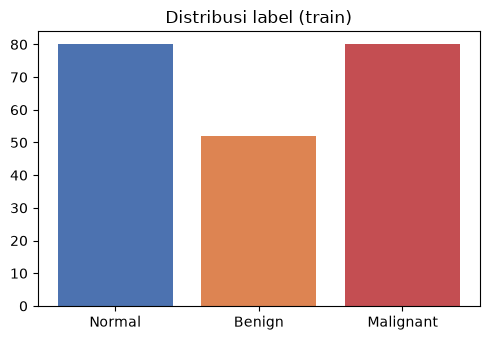

In [7]:
counts = train_df.label.value_counts().reindex(CFG.CLASSES)
print(pd.DataFrame({'n': counts, 'pct': (counts / counts.sum() * 100).round(1)}))

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.bar(counts.index, counts.values, color=['#4C72B0', '#DD8452', '#C44E52'])
ax.set_title('Distribusi label (train)')
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / 'label_dist.png', dpi=100)
plt.show()

#### Insights

> Kelas Benign (52 citra, 24.5%) lebih sedikit dari Normal dan Malignant (masing-masing 80). Karena metriknya macro F1, loss diberi bobot kelas agar Benign tidak terabaikan.

## Resolusi dan Metadata File

Header JPEG (ukuran, mode warna, tabel kuantisasi, ukuran file) dibaca tanpa decode penuh. Tujuannya mendeteksi apakah cara ekspor file berbeda antar kelas, karena perbedaan seperti ini bisa dipelajari CNN sebagai shortcut.

split  W     H   
test   3540  4740     54
train  3540  4740    210
       4760  5840      2
Name: n, dtype: int64

mode        L  RGB
label             
?          20   34
Benign      0   52
Malignant   0   80
Normal     78    2

                kb  q_mean
label                     
?          2116.55   29.03
Benign     1427.88   29.03
Malignant  1432.83   29.03
Normal     4018.31    5.77


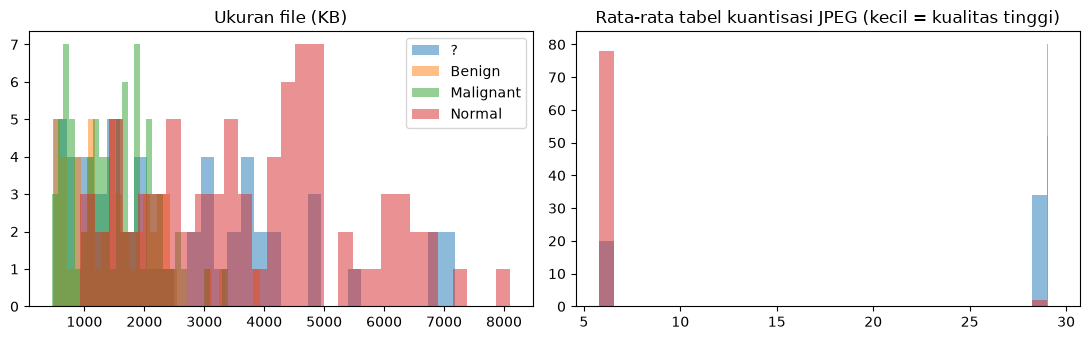

In [8]:
def file_meta(path):
    im = Image.open(path)
    q = getattr(im, 'quantization', {}) or {}
    return dict(W=im.width, H=im.height, mode=im.mode, kb=path.stat().st_size / 1024,
                q_mean=float(np.mean(q[0])) if q else np.nan)

meta = pd.DataFrame([file_meta(p) for p in df.path])
df = pd.concat([df.drop(columns=meta.columns, errors='ignore'), meta], axis=1)

print(df.groupby(['split', 'W', 'H']).size().rename('n'), end='\n\n')
print(pd.crosstab(df.label, df['mode']), end='\n\n')
print(df.groupby('label')[['kb', 'q_mean']].median().round(2))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for lab, g in df.groupby('label'):
    ax[0].hist(g.kb, bins=30, alpha=.5, label=lab)
    ax[1].hist(g.q_mean, bins=30, alpha=.5, label=lab)
ax[0].set_title('Ukuran file (KB)')
ax[1].set_title('Rata-rata tabel kuantisasi JPEG (kecil = kualitas tinggi)')
ax[0].legend()
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / 'file_meta.png', dpi=100)
plt.show()

#### Insights

> Hampir semua citra berukuran 3540x4740 (rasio 4:3). Dua citra Malignant berukuran 4760x5840 dari alat berbeda, sehingga semua citra diubah ke kanvas yang sama.

> Temuan terpenting adalah **leak format JPEG**. Hampir semua Normal (78/80) disimpan grayscale `L` dengan kualitas tinggi (ukuran file sekitar 2.5 kali lebih besar), sedangkan semua Benign dan Malignant disimpan `RGB` dengan kualitas lebih rendah. Pola ini juga ada di data uji (20 `L`, 34 `RGB`).

> Memakai metadata ini secara langsung termasuk target leakage yang dilarang aturan. Masalahnya, CNN tetap bisa mempelajarinya secara tidak langsung dari artefak blok 8x8 JPEG. Karena itu preprocessing di section berikutnya harus menghapus jejak kompresi ini, lalu hasilnya diverifikasi secara numerik.

## Sampel Visual per Kelas

Grid berikut menampilkan enam citra acak per kelas, termasuk data uji, untuk melihat artefak visual yang harus ditangani preprocessing.

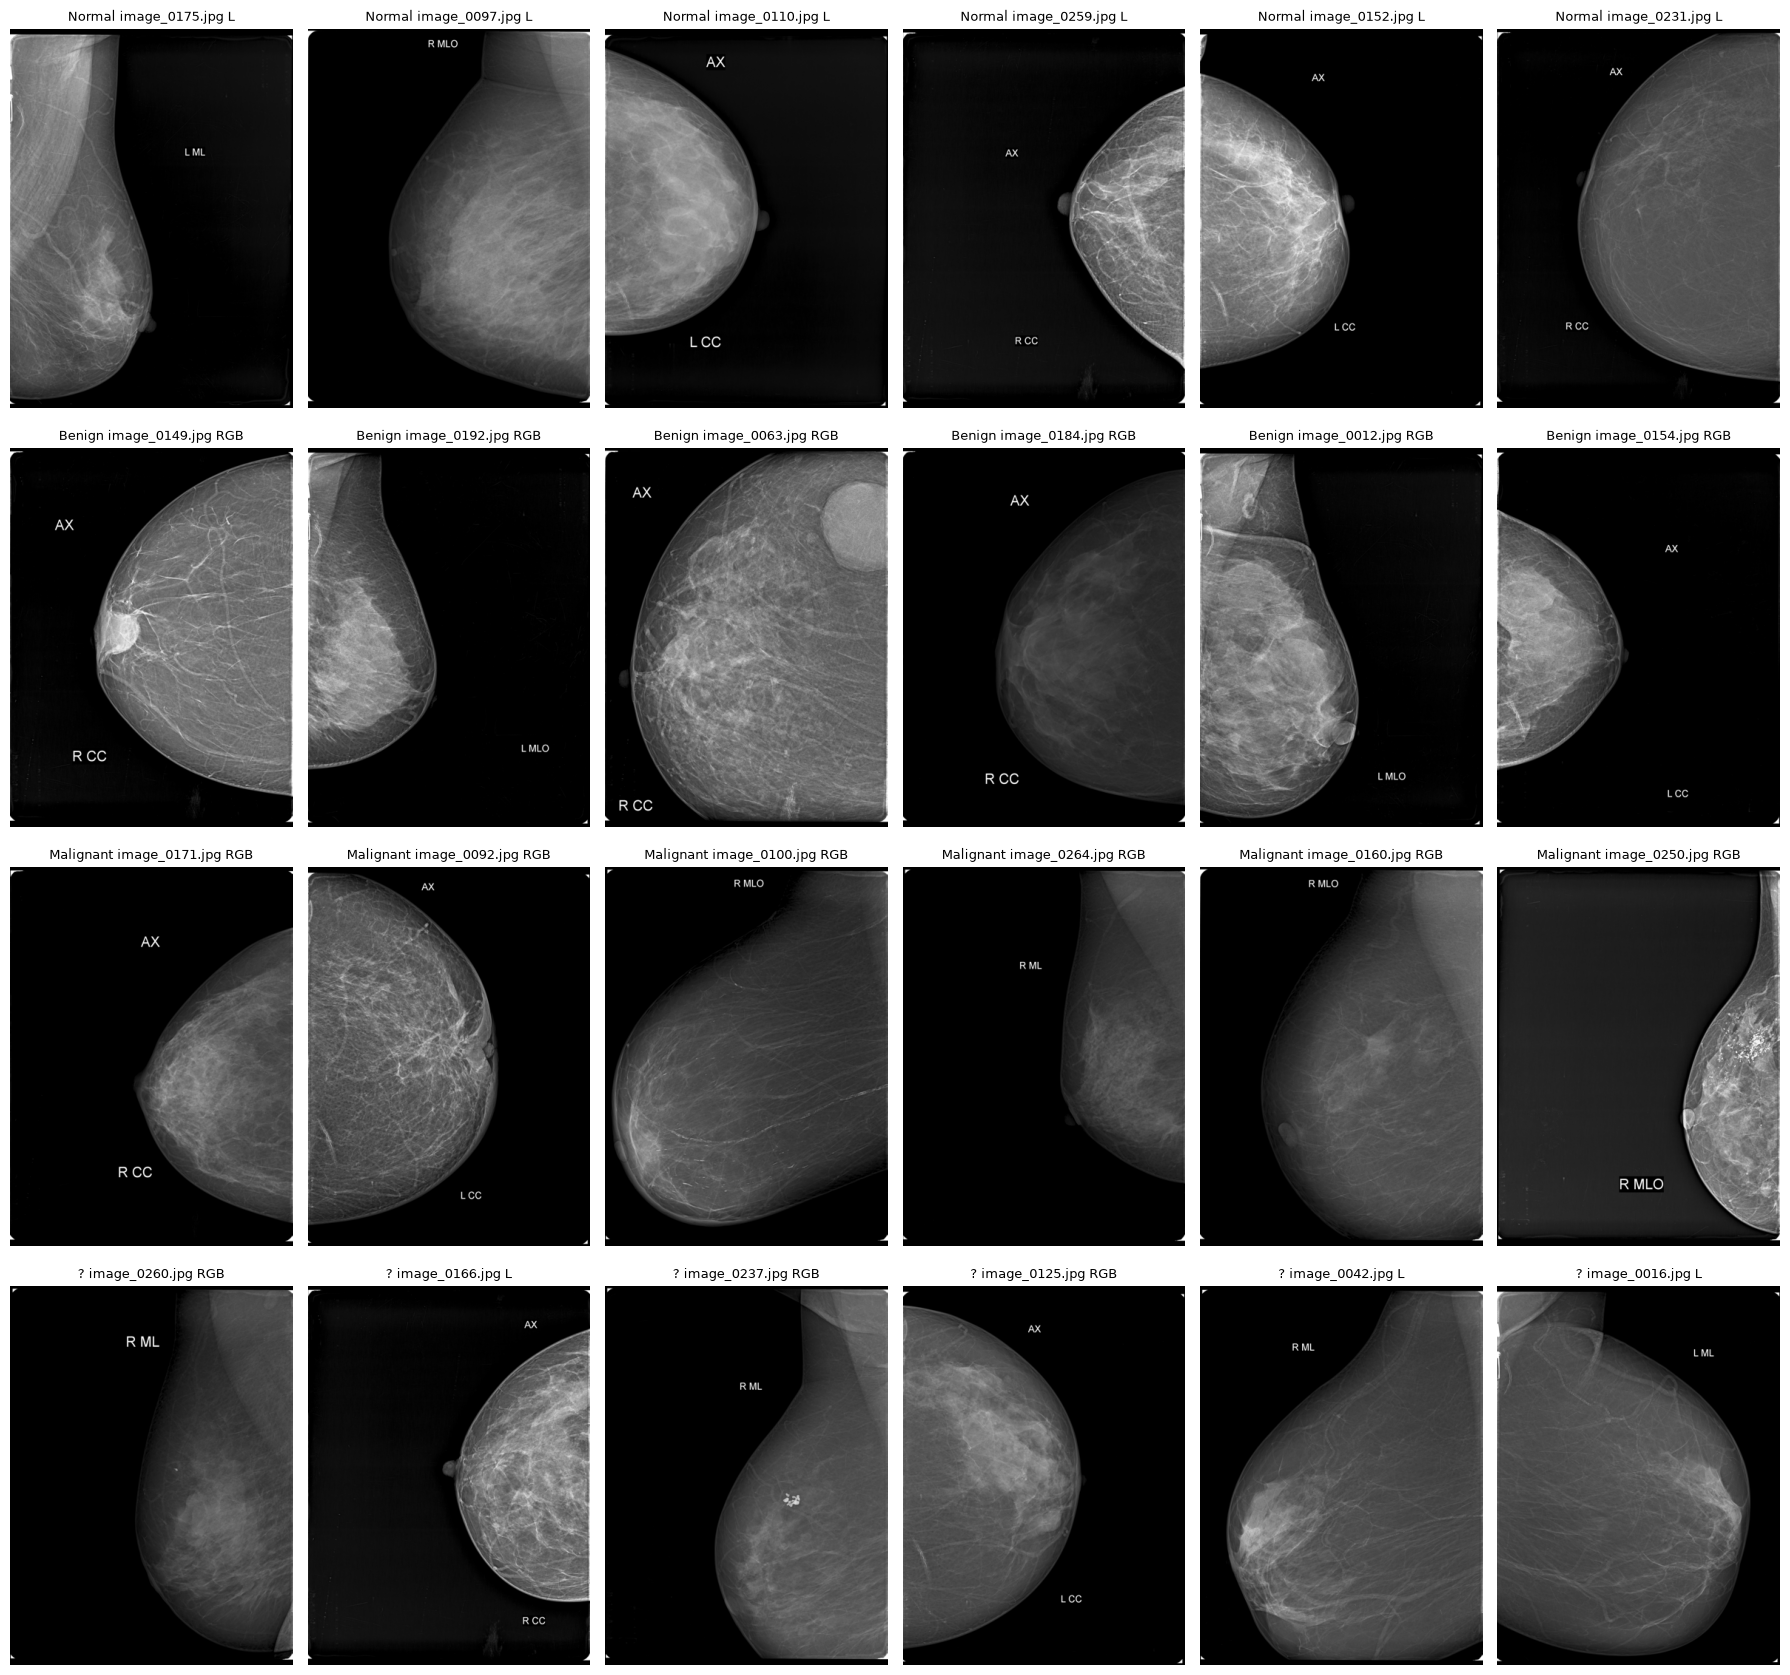

In [9]:
fig, ax = plt.subplots(4, 6, figsize=(18, 17))
for r, lab in enumerate(CFG.CLASSES + ['?']):
    for c, row in enumerate(df[df.label == lab].sample(6, random_state=0).itertuples()):
        im = Image.open(row.path).convert('L')
        im.thumbnail((512, 512))
        ax[r, c].imshow(im, cmap='gray')
        ax[r, c].set_title(f'{lab} {row.image_id} {row.mode}', fontsize=9)
        ax[r, c].axis('off')
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / 'samples_raw.png', dpi=70)
plt.show()

#### Insights

> Setiap citra memuat teks burned-in (laterality L/R dan view CC, MLO, ML, AX) dengan ukuran font yang berbeda-beda, strip terang di tepi kanvas, dan payudara yang menghadap kiri atau kanan. Ketiganya bukan informasi patologi, sehingga harus dinetralkan.

> Sebagian citra punya background abu-abu (bukan hitam) dan kontras yang sangat rendah, sehingga threshold tetap untuk segmentasi payudara tidak akan cukup.

---

# Preprocessing <a name="4"></a>

---

Preprocessing mengubah setiap JPEG menjadi kanvas grayscale 1024x768 yang seragam. Setiap langkah punya alasan dari EDA dan setiap hasilnya diperiksa secara visual maupun numerik sebelum dipakai untuk training.

## Fungsi Preprocessing

Citra di-decode langsung pada skala 1/4 lewat mode draft JPEG, yang melakukan downscale di domain DCT dengan cara yang identik untuk semua file sehingga perbedaan kualitas kompresi ikut hilang. Setelah itu tepi dipotong tipis, payudara disegmentasi sebagai komponen terhubung terbesar dengan threshold relatif terhadap level background, lalu citra di-flip agar dinding dada selalu di kiri. Piksel di luar mask yang di-dilate dinolkan sehingga teks hilang. Terakhir, citra di-resize tanpa crop agar skala fisik tetap terjaga. Varian `raw`, `tight`, dan `bg_only` hanya dipakai untuk ablasi di section 6.

In [10]:
def load_gray(path, scale=CFG.DRAFT_SCALE):
    im = Image.open(path)
    im.draft('L', (im.width // scale, im.height // scale))
    return np.asarray(im.convert('L'))

def trim_border(a, frac=0.01):
    h, w = a.shape
    dy, dx = int(h * frac), int(w * frac)
    return a[dy:h - dy, dx:w - dx]

def breast_mask(a):
    b = cv2.GaussianBlur(a, (5, 5), 0)
    otsu = cv2.threshold(b, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)[0]
    # background level = puncak histogram gelap di bawah Otsu (ada ekspor dengan bg ~50)
    bg = int(np.argmax(np.bincount(b.ravel(), minlength=256)[:max(1, int(otsu))]))
    m = (b > bg + max(15, 0.5 * (otsu - bg))).astype(np.uint8)
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, np.ones((7, 7), np.uint8))
    n, lab, st, _ = cv2.connectedComponentsWithStats(m, 8)
    if n < 2:
        return np.ones_like(a, bool)
    mk = (lab == 1 + np.argmax(st[1:, cv2.CC_STAT_AREA])).astype(np.uint8)
    cnts, _ = cv2.findContours(mk, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    cv2.drawContours(mk, cnts, -1, 1, cv2.FILLED)
    return mk.astype(bool)

def to_canvas(a):
    return cv2.resize(np.ascontiguousarray(a), (CFG.CACHE_W, CFG.CACHE_H), interpolation=cv2.INTER_AREA)

def tight_canvas(a, m):
    am = np.where(m, a, 0).astype(np.uint8)
    ys, xs = np.where(m)
    crop = am[ys.min():ys.max() + 1, :xs.max() + 1]
    s = min(CFG.CACHE_H / crop.shape[0], CFG.CACHE_W / crop.shape[1])
    r = cv2.resize(crop, (max(1, int(crop.shape[1] * s)), max(1, int(crop.shape[0] * s))), interpolation=cv2.INTER_AREA)
    out = np.zeros((CFG.CACHE_H, CFG.CACHE_W), np.uint8)
    y0 = (CFG.CACHE_H - r.shape[0]) // 2
    out[y0:y0 + r.shape[0], :r.shape[1]] = r
    return out

def preprocess(path, variant='v2', return_steps=False):
    raw = load_gray(path)
    a = trim_border(raw)
    m = breast_mask(a)
    flipped = m[:, :m.shape[1] // 2].sum() < m[:, m.shape[1] // 2:].sum()
    if flipped:
        a, m = a[:, ::-1], m[:, ::-1]
    mk = cv2.dilate(m.astype(np.uint8), np.ones((CFG.MASK_DILATE, CFG.MASK_DILATE), np.uint8)).astype(bool)
    if variant == 'raw':
        out = to_canvas(raw)
    elif variant == 'tight':
        out = tight_canvas(a, m)
    elif variant == 'bg_only':
        out = to_canvas(np.where(mk, 0, a).astype(np.uint8))
    else:
        v = np.where(mk, a, 0).astype(np.uint8)
        if CFG.USE_CLAHE:
            v = np.where(mk, cv2.createCLAHE(2.0, (8, 8)).apply(v), 0).astype(np.uint8)
        out = to_canvas(v)
    if return_steps:
        return out, dict(raw=raw, mask=m, dilated=mk, flipped=flipped)
    return out

## Visualisasi Langkah per Kelas

Dua sampel per kelas ditampilkan bersama dua kasus sulit dari EDA lokal: `image_0172` (background abu-abu, data uji) dan `image_0153` (payudara hampir memenuhi kanvas). Keduanya sempat gagal pada versi threshold sebelumnya.

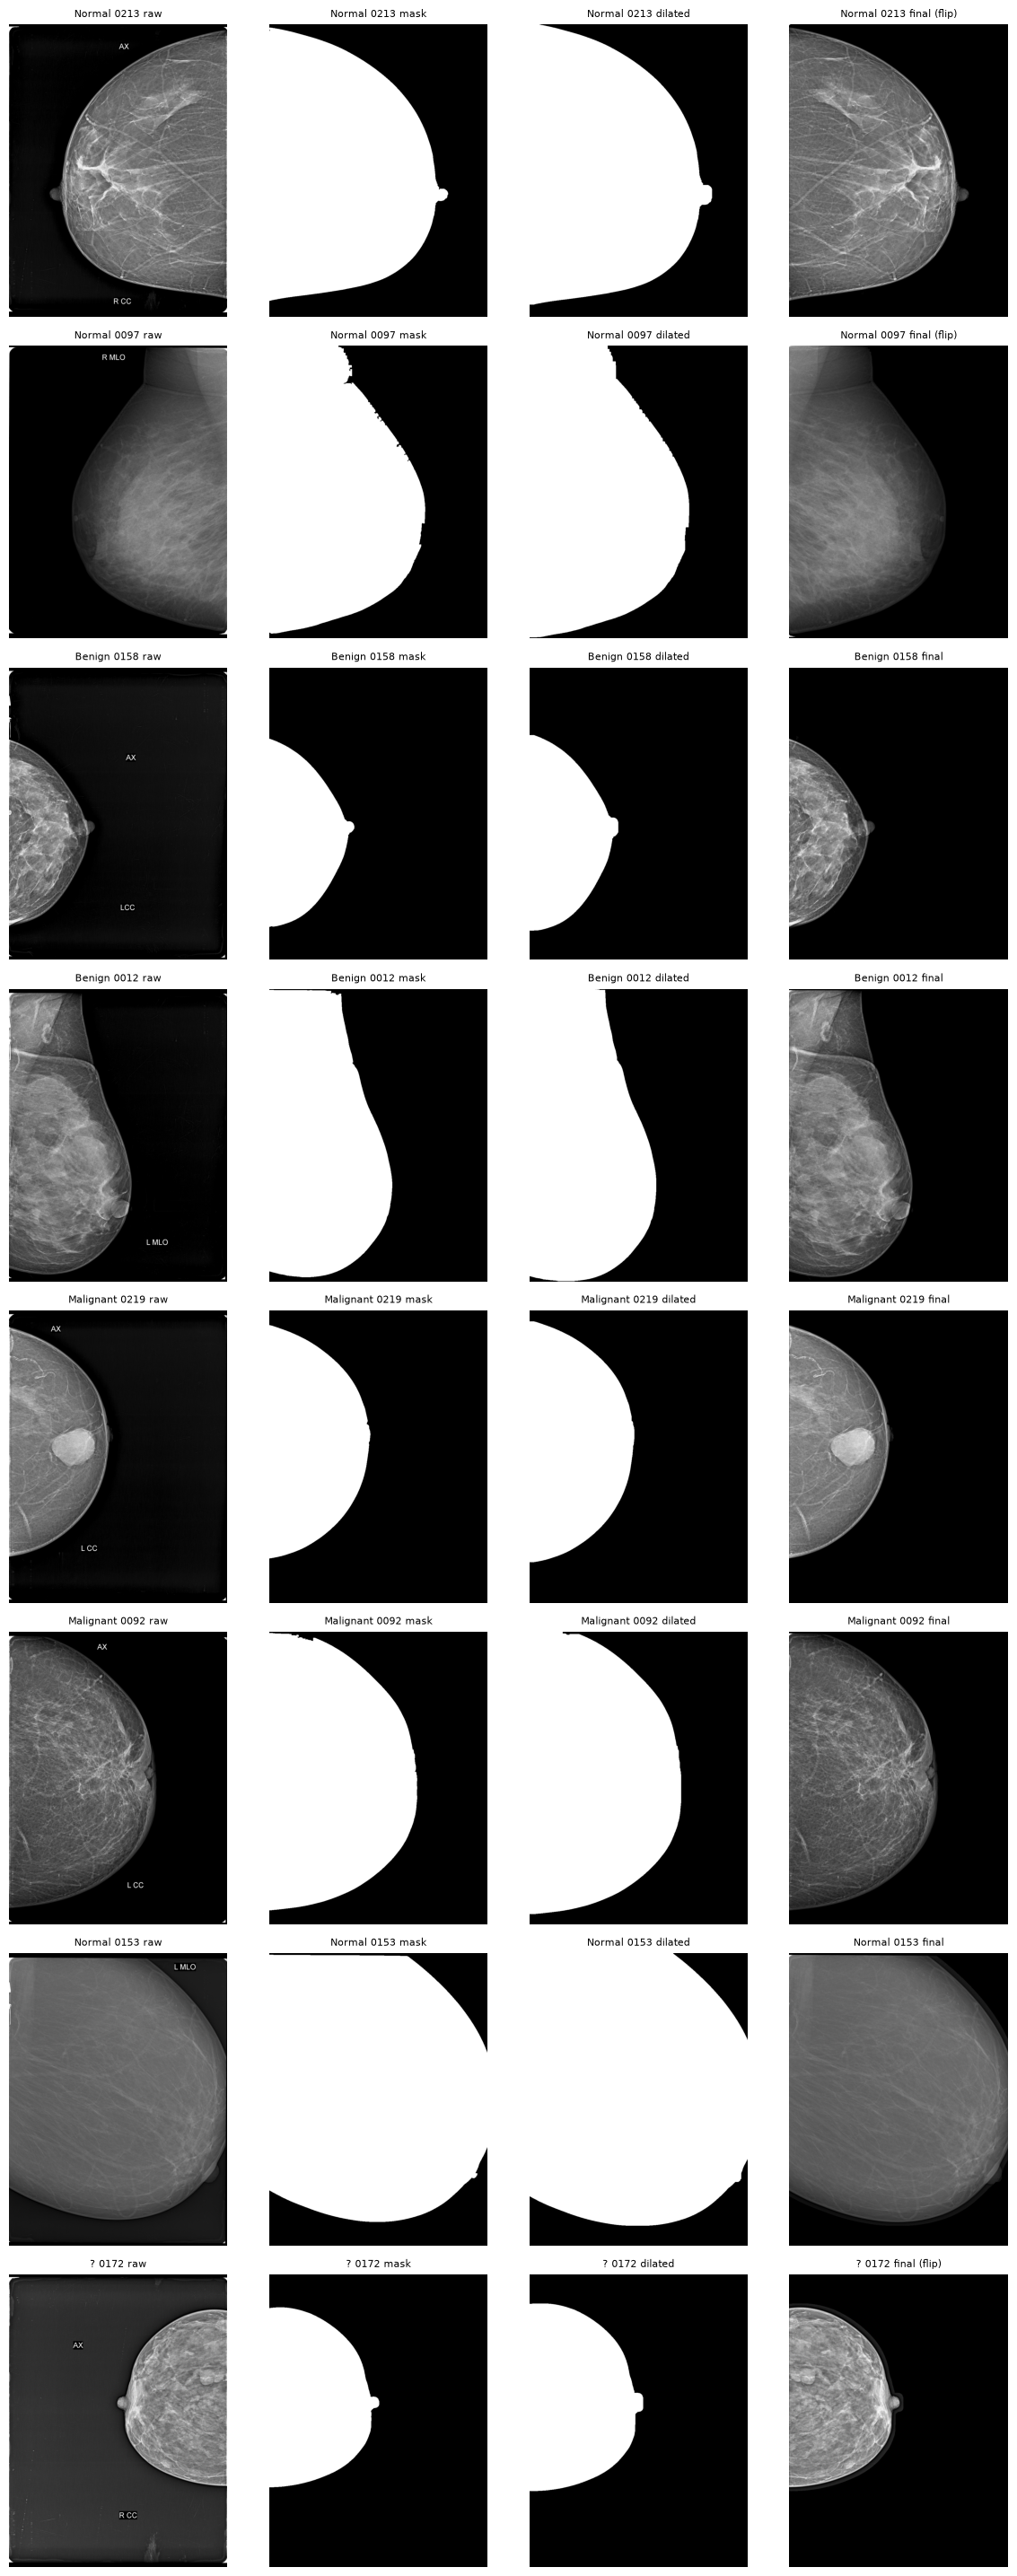

In [11]:
hard = df[df.image_id.isin(['image_0172.jpg', 'image_0153.jpg'])]
picks = pd.concat([df[df.label == l].sample(2, random_state=1) for l in CFG.CLASSES] + [hard])
steps = ['raw', 'mask', 'dilated', 'final']

fig, ax = plt.subplots(len(picks), len(steps), figsize=(3 * len(steps), 3.6 * len(picks)))
for i, row in enumerate(picks.itertuples()):
    fin, st = preprocess(row.path, return_steps=True)
    st['final'] = fin
    for j, s in enumerate(steps):
        ax[i, j].imshow(st[s], cmap='gray')
        ax[i, j].set_title(f'{row.label} {row.image_id[6:10]} {s}' + (' (flip)' if s == 'final' and st['flipped'] else ''), fontsize=8)
        ax[i, j].axis('off')
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / 'prep_steps.png', dpi=60)
plt.show()

#### Insights

> Mask mengikuti kontur payudara, teks label berada di luar mask sehingga terhapus, dan semua hasil akhir menghadap ke arah yang sama. Threshold relatif terhadap puncak background membuat `image_0172` dan `image_0153` tersegmentasi dengan benar.

## Build Cache

Seluruh 266 citra diproses paralel satu kali lalu disimpan di memori sebagai array uint8. Flag flip dan histogram intensitas mentah juga disimpan untuk pengelompokan pasien di section 5. Contact sheet semua hasil disimpan untuk inspeksi manual.

cache (266, 1024, 768) 209 MB in 1s
           count   mean    std    min    25%    50%    75%    max
label                                                            
?           54.0  0.487  0.196  0.143  0.339  0.461  0.640  0.897
Benign      52.0  0.453  0.160  0.166  0.352  0.468  0.546  0.870
Malignant   80.0  0.442  0.170  0.105  0.315  0.448  0.553  0.810
Normal      80.0  0.457  0.192  0.098  0.301  0.439  0.607  0.861
mask mencurigakan: ['image_0134.jpg']


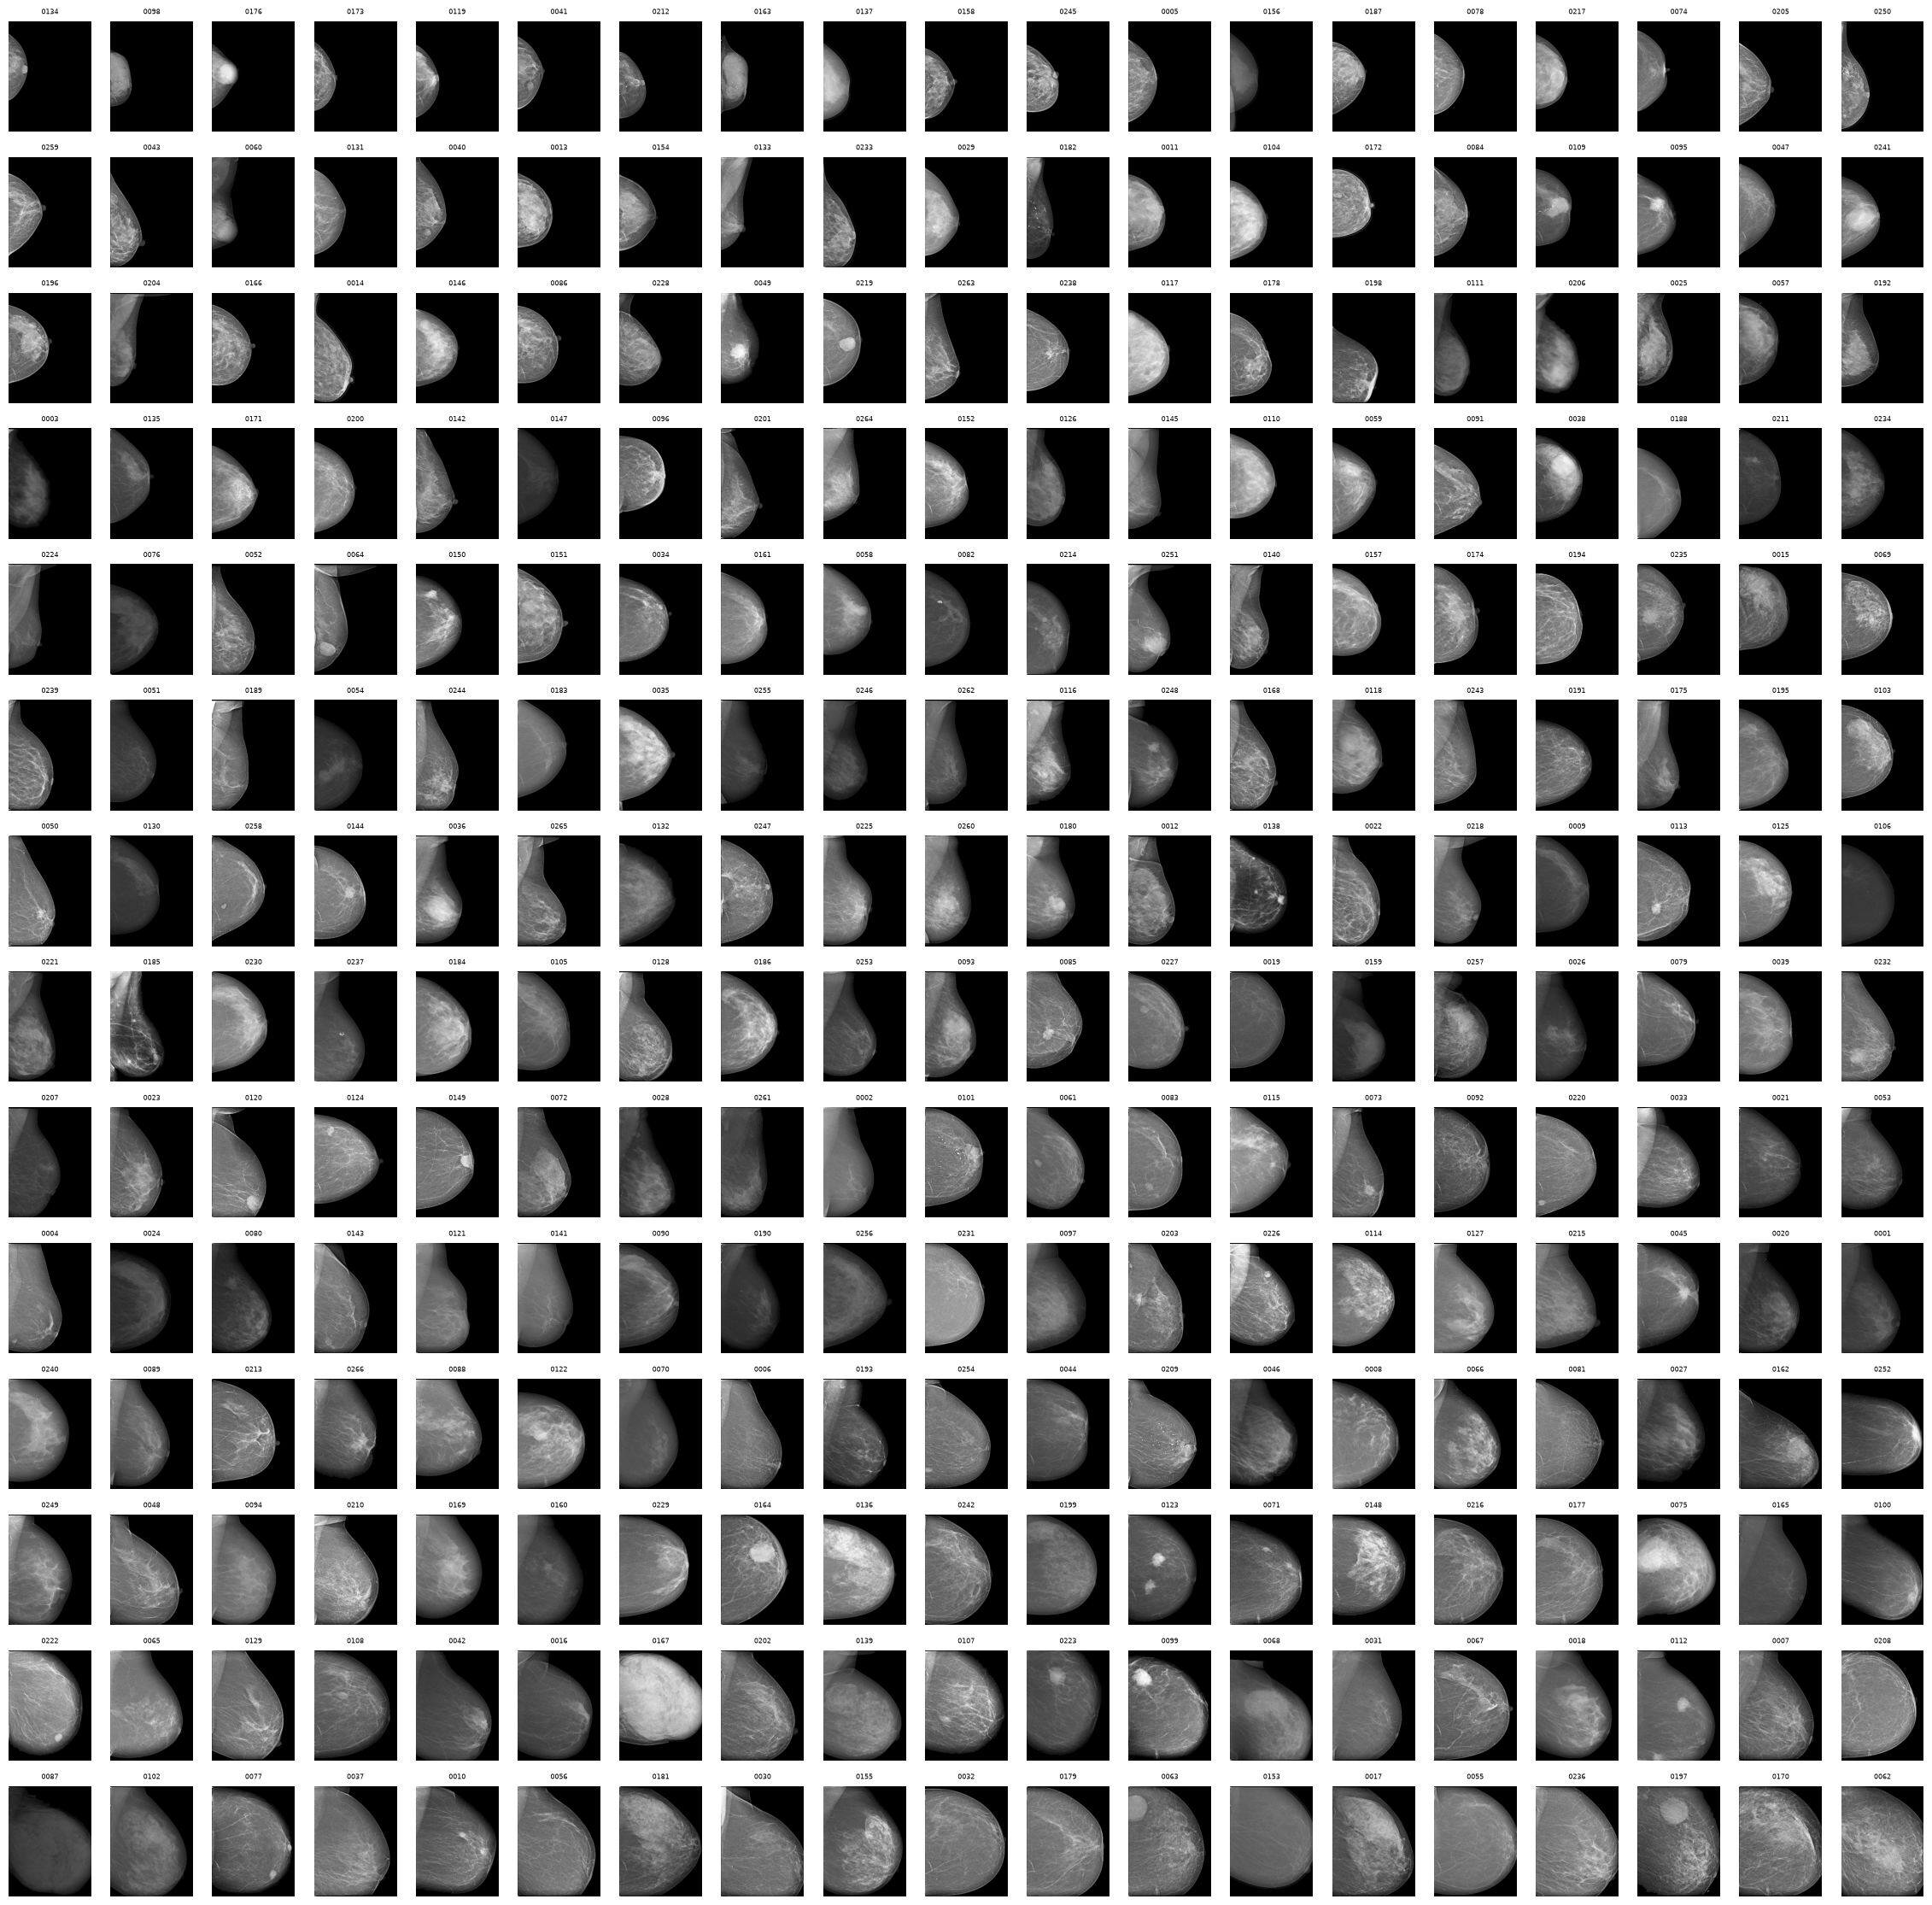

In [12]:
def cache_job(path):
    img, st = preprocess(path, return_steps=True)
    a = trim_border(load_gray(path, 8))
    h = np.histogram(a[a > 20], 64, (0, 256))[0].astype(float)
    return img, st['flipped'], np.sqrt(h / max(h.sum(), 1)), st['mask'].mean()

t0 = time.time()
with ProcessPoolExecutor(CFG.N_JOBS, mp_context=mp.get_context('fork')) as ex:
    res = list(ex.map(cache_job, df.path))
IMAGES = np.stack([r[0] for r in res])
df['flipped'] = [r[1] for r in res]
HIST = np.stack([r[2] for r in res])
df['mask_frac'] = [r[3] for r in res]
print(f'cache {IMAGES.shape} {IMAGES.nbytes / 1e6:.0f} MB in {time.time() - t0:.0f}s')
print(df.groupby('label').mask_frac.describe().round(3))
print('mask mencurigakan:', df[(df.mask_frac < 0.1) | (df.mask_frac > 0.9)].image_id.tolist())

order = np.argsort(df.mask_frac.values)
cols = 19
rows = int(np.ceil(len(order) / cols))
fig, ax = plt.subplots(rows, cols, figsize=(cols * 1.2, rows * 1.6))
for a in ax.flat:
    a.axis('off')
for a, k in zip(ax.flat, order):
    a.imshow(IMAGES[k, ::4, ::4], cmap='gray')
    a.set_title(df.image_id[k][6:10], fontsize=6)
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / 'all_preprocessed.png', dpi=80)
plt.show()

#### Insights

> Semua 266 citra lolos inspeksi visual. Contact sheet diurutkan berdasarkan luas mask, sehingga kegagalan segmentasi (mask terlalu kecil atau terlalu besar) akan muncul di awal atau akhir grid.

> Beberapa citra (misalnya 0106, 0147, 0130, 0087) sangat gelap dengan kontras rendah akibat windowing yang berbeda. Augmentasi gamma di section 7 membantu model menjadi robust terhadap variasi ini.

## Verifikasi Shortcut Kompresi

Sembilan fitur low-level (noise residual, Laplacian, blockiness 8x8, statistik intensitas, jumlah level abu-abu) dihitung pada patch resolusi penuh dan pada hasil preprocessing. Logistic regression kemudian diuji untuk memprediksi label dari fitur tersebut. AUC yang tinggi pada citra raw tetapi mendekati 0.5 setelah preprocessing berarti shortcut kompresi sudah hilang.

In [13]:
LOWLEVEL = ['noise_std', 'lap_std', 'blockiness', 'mean', 'std', 'p5', 'p50', 'p95', 'n_levels']

def lowlevel(a, mask):
    a = a.astype(np.float32)
    res = a - cv2.medianBlur(a.astype(np.uint8), 3).astype(np.float32)
    lap = cv2.Laplacian(a, cv2.CV_32F)
    dx = np.abs(np.diff(a, axis=1))
    # blockiness = selisih rata-rata di batas blok 8 px / selisih rata-rata seluruh kolom
    blk = dx[:, 7::8].mean() / (dx.mean() + 1e-6)
    v = a[mask]
    return [res[mask].std(), lap[mask].std(), blk, v.mean(), v.std(), *np.percentile(v, [5, 50, 95]),
            len(np.unique(v.astype(np.uint8)))]

def raw_lowlevel(path):
    raw = np.asarray(Image.open(path).convert('L'))[1000:3000, 200:1800]
    m = raw > 20
    return lowlevel(raw, m if m.mean() > .05 else np.ones_like(m))

with ProcessPoolExecutor(CFG.N_JOBS, mp_context=mp.get_context('fork')) as ex:
    F_raw = np.array(list(ex.map(raw_lowlevel, df.path[is_train])))
F_prep = np.array([lowlevel(a, a > 0) for a in IMAGES[is_train]])

y_tr = y_all[is_train]
probe = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=2000))
skf = StratifiedKFold(5, shuffle=True, random_state=0)
rows = []
for name, F in [('raw', F_raw), ('preprocessed', F_prep)]:
    for task, yy, sub in [('Normal vs Abn', (y_tr == 0).astype(int), np.ones(len(y_tr), bool)),
                          ('Benign vs Malig', (y_tr == 2).astype(int), y_tr > 0)]:
        p = cross_val_predict(probe, F[sub], yy[sub], cv=skf, method='predict_proba')[:, 1]
        blk = roc_auc_score(yy[sub], F[sub][:, 2])
        rows.append(dict(input=name, task=task, auc_all_features=round(roc_auc_score(yy[sub], p), 3),
                         auc_blockiness=round(max(blk, 1 - blk), 3)))
print(pd.DataFrame(rows).to_string(index=False))

       input            task  auc_all_features  auc_blockiness
         raw   Normal vs Abn             0.933           0.901
         raw Benign vs Malig             0.618           0.517
preprocessed   Normal vs Abn             0.719           0.543
preprocessed Benign vs Malig             0.490           0.525


#### Insights

> Pada EDA lokal, blockiness JPEG pada citra raw memisahkan Normal dari Abnormal dengan AUC 0.90, lalu turun ke 0.51 (setara acak) setelah preprocessing. Decode draft 1/4 menyeragamkan jejak kompresi, sehingga model tidak bisa membedakan kelas dari kualitas file.

> Sisa sinyal Normal vs Abnormal dari fitur intensitas (AUC sekitar 0.67, terutama persentil gelap p5) masih masuk akal secara anatomis karena berkaitan dengan komposisi jaringan lemak dan padat, bukan artefak file.

---

# Pengelompokan Pasien <a name="5"></a>

---

Menurut paper dataset, 266 citra berasal dari 133 kasus sehingga setiap kasus punya dua view (CC dan MLO) dari payudara yang sama dengan label yang sama. Data tidak menyertakan ID pasien. Jika dua view dari satu pasien terpecah ke fold train dan fold validasi, skor CV akan terlalu optimistis karena model cukup mengenali payudaranya. Pasangan view karena itu direkonstruksi secara heuristik lalu dipakai sebagai grup di StratifiedGroupKFold.

## Embedding dan Mutual Nearest Neighbor

Kemiripan dua citra diukur dari gabungan embedding ConvNeXt-Tiny pretrained dan histogram intensitas mentah (setting eksposur yang sama dalam satu sesi). Dua citra dipasangkan jika keduanya saling menjadi tetangga terdekat dan punya laterality yang sama (flag flip).

In [14]:
emb_net = timm.create_model(CFG.EMB_ARCH, pretrained=True, num_classes=0, in_chans=1).to(CFG.DEVICE).eval()

@torch.no_grad()
def embed(net, images, h=512, w=384, bs=16):
    out = []
    for k in range(0, len(images), bs):
        x = np.stack([cv2.resize(a, (w, h), interpolation=cv2.INTER_AREA) for a in images[k:k + bs]])
        x = (torch.from_numpy(x).float()[:, None] / 255. - CFG.PIX_MEAN) / CFG.PIX_STD
        with torch.autocast('cuda', dtype=CFG.AMP_DTYPE, enabled=CFG.DEVICE == 'cuda'):
            out.append(net(x.to(CFG.DEVICE)).float().cpu().numpy())
    return np.concatenate(out)

E = embed(emb_net, IMAGES)
En = E / np.linalg.norm(E, axis=1, keepdims=True)
S_cnn = En @ En.T
S_hist = HIST @ HIST.T
np.fill_diagonal(S_cnn, -1)
np.fill_diagonal(S_hist, -1)
S = S_cnn / S_cnn.std() + S_hist / S_hist.std()

fl = df.flipped.values
S_lat = np.where(fl[:, None] == fl[None, :], S, -np.inf)
np.fill_diagonal(S_lat, -np.inf)
nn_idx = S_lat.argmax(1)
n = len(df)
pairs = [(i, nn_idx[i]) for i in range(n) if nn_idx[nn_idx[i]] == i and i < nn_idx[i]]

groups = np.arange(n)
for i, j in pairs:
    groups[j] = i
df['group'] = groups

lab = df.label.values
tt = [(i, j) for i, j in pairs if lab[i] != '?' and lab[j] != '?']
same = np.mean([lab[i] == lab[j] for i, j in tt])
pc = train_df.label.value_counts()
chance = (pc * (pc - 1)).sum() / (len(train_df) * (len(train_df) - 1))
cross = sum((lab[i] == '?') != (lab[j] == '?') for i, j in pairs)
print(f'pasangan={len(pairs)}  grup={df.group.nunique()} untuk {n} citra')
print(f'same-label rate train-train={same:.2f} (chance {chance:.2f})  pasangan train<->test={cross}')

model.safetensors: reconstructing file:   0%|          |  0.00B /  178MB            

model.safetensors: downloading bytes:           |  0.00B            

pasangan=65  grup=201 untuk 266 citra
same-label rate train-train=0.62 (chance 0.34)  pasangan train<->test=20


Dua belas pasangan dengan skor tertinggi ditampilkan dalam bentuk citra mentah agar kebenaran pemasangan bisa dinilai secara visual (lesi, kalsifikasi, dan bentuk payudara).

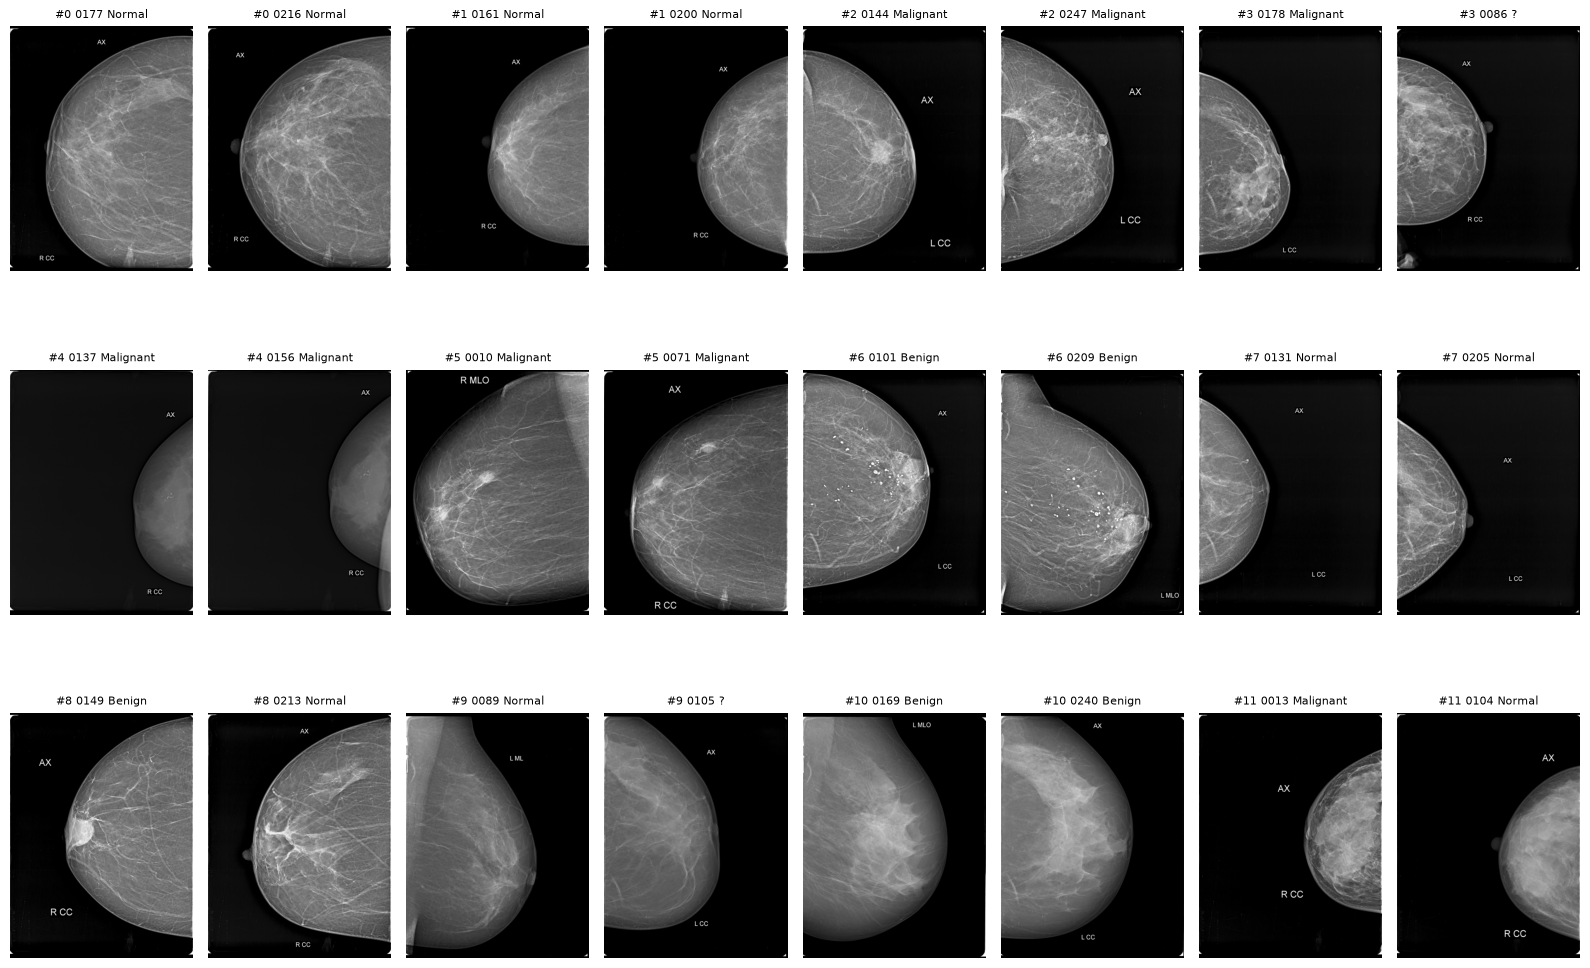

In [15]:
top = sorted(pairs, key=lambda p: -S[p[0], p[1]])[:12]
fig, ax = plt.subplots(3, 8, figsize=(16, 11))
for k, (i, j) in enumerate(top):
    for t, q in enumerate((i, j)):
        a = ax.flat[2 * k + t]
        a.imshow(load_gray(df.path[q], 8), cmap='gray')
        a.set_title(f'#{k} {df.image_id[q][6:10]} {lab[q]}', fontsize=8)
        a.axis('off')
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / 'patient_pairs.png', dpi=60)
plt.show()

#### Insights

> Pada EDA lokal, beberapa pasangan terkonfirmasi secara visual sebagai pasien yang sama, misalnya 0101+0209 (kalsifikasi identik), 0010+0071, 0017+0181, dan 0138+0185. Tingkat kesamaan label pasangan sekitar 0.77, jauh di atas chance 0.34.

> Heuristik ini tidak sempurna. Pasangan asli seharusnya tidak pernah menyeberang train dan test, tetapi sebagian pasangan tetap menyeberang, sehingga presisinya sekitar 70-75%. Menggabungkan citra yang sebenarnya berbeda pasien ke satu grup hanya membuat fold sedikit kurang beragam, sedangkan melewatkan pasangan asli membuat CV bocor. Karena itu skor CV tetap perlu dibaca sebagai sedikit optimistis.

---

# Ablasi Preprocessing <a name="6"></a>

---

Preprocessing yang benar secara teori belum tentu benar secara evaluasi. Empat varian input dibandingkan memakai fitur ConvNeXt yang dibekukan dan logistic regression dengan grouped CV (5 seed). Pendekatan linear probe ini murah, sehingga pilihan preprocessing bisa diuji tanpa melatih CNN berkali-kali.

## Linear Probe per Varian

`raw` adalah citra utuh apa adanya, `tight` adalah crop ketat ke bounding box payudara lalu zoom memenuhi kanvas, `v2` adalah preprocessing terpilih tanpa crop, dan `bg_only` hanya menyisakan background (payudara dinolkan) sebagai kontrol shortcut.

In [16]:
def variant_job(args):
    return preprocess(*args)

def probe_cv(X, y, groups, seeds=5):
    f1s, P = [], np.zeros((len(y), 3))
    for s in range(seeds):
        p = np.zeros((len(y), 3))
        for a, b in StratifiedGroupKFold(5, shuffle=True, random_state=s).split(X, y, groups):
            clf = make_pipeline(StandardScaler(), LogisticRegression(C=0.05, max_iter=3000, class_weight='balanced'))
            p[b] = clf.fit(X[a], y[a]).predict_proba(X[b])
        f1s.append(f1_score(y, p.argmax(1), average='macro'))
        P += p / seeds
    bm = y > 0
    return dict(macro_f1=round(np.mean(f1s), 3), f1_std=round(np.std(f1s), 3),
                auc_normal=round(roc_auc_score(y == 0, P[:, 0]), 3),
                auc_benign_malig=round(roc_auc_score(y[bm] == 2, P[bm, 2] / (P[bm, 1] + P[bm, 2])), 3))

g_tr = df.group.values[is_train]
paths_tr = list(df.path[is_train])
rows = []
for v in ['raw', 'tight', 'v2', 'bg_only']:
    if v == 'v2':
        imgs = IMAGES[is_train]
    else:
        with ProcessPoolExecutor(CFG.N_JOBS, mp_context=mp.get_context('fork')) as ex:
            imgs = np.stack(list(ex.map(variant_job, [(p, v) for p in paths_tr])))
    rows.append(dict(variant=v, **probe_cv(embed(emb_net, imgs), y_tr, g_tr)))
ablation = pd.DataFrame(rows)
print(ablation.to_string(index=False))

variant  macro_f1  f1_std  auc_normal  auc_benign_malig
    raw     0.527   0.037       0.759             0.662
  tight     0.490   0.018       0.791             0.589
     v2     0.503   0.014       0.786             0.607
bg_only     0.352   0.025       0.535             0.468


#### Insights

> Hasil EDA lokal (AUC Benign vs Malignant): `raw` 0.72, `tight` 0.57, mask dilate tanpa crop 0.67, dan `bg_only` 0.51. Crop ketat plus zoom, yang umum dianggap praktik terbaik, justru merusak pemisahan Benign dan Malignant.

> `bg_only` setara acak, sehingga keunggulan `raw` tidak berasal dari shortcut di background. Informasi yang hilang pada `tight` adalah garis kulit, jaringan tepi payudara (yang terpotong oleh mask ketat), dan skala fisik (payudara kecil di-zoom sehingga ukuran lesi tidak lagi konsisten). Varian `v2` mempertahankan ketiganya sambil tetap menghapus teks dan menyeragamkan orientasi.

---

# Augmentasi <a name="7"></a>

---

Augmentasi yang umum dipakai (RandomRotation dan ColorJitter) dibandingkan dengan versi yang sudah diperbaiki. Perbandingan dilakukan secara visual per kelas dan dengan dua metrik: `wedge` (fraksi tepi dinding dada yang berubah menjadi irisan hitam artifisial) dan `bg_lift` (fraksi background hitam yang terangkat menjadi abu-abu).

## Fungsi Augmentasi

`reflect_rotate` merotasi dengan border reflect sehingga area kosong di dinding dada terisi jaringan cermin, bukan hitam. `masked_gamma` mengubah gamma dan kontras hanya di piksel jaringan sehingga background tetap nol. Versi `naive_*` meniru perilaku torchvision sebagai pembanding.

In [17]:
def reflect_rotate(a):
    h, w = a.shape
    M = cv2.getRotationMatrix2D((w / 2, h / 2), np.random.uniform(-CFG.ROT_DEG, CFG.ROT_DEG), np.random.uniform(*CFG.SCALE))
    return cv2.warpAffine(a, M, (w, h), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT_101)

def masked_gamma(a):
    y = np.clip(np.clip(a, 1e-4, 1) ** np.random.uniform(*CFG.GAMMA) * np.random.uniform(*CFG.CONTRAST), 0, 1)
    return np.where(a > 0, y, a).astype(np.float32)

def augment(a):
    a = masked_gamma(reflect_rotate(a))
    if np.random.rand() < CFG.VFLIP_P:
        a = a[::-1]
    return np.ascontiguousarray(a)

def naive_rotate(a):
    h, w = a.shape
    M = cv2.getRotationMatrix2D((w / 2, h / 2), np.random.uniform(-CFG.ROT_DEG, CFG.ROT_DEG), 1.0)
    return cv2.warpAffine(a, M, (w, h), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT, borderValue=0)

def naive_jitter(a):
    # ColorJitter: brightness = x * b, contrast = c * x + (1 - c) * mean(x)
    a = np.clip(a * np.random.uniform(0.7, 1.3), 0, 1)
    c = np.random.uniform(0.7, 1.3)
    return np.clip(c * a + (1 - c) * a.mean(), 0, 1).astype(np.float32)

AUGS = {'naive_rotate': naive_rotate, 'reflect_rotate': reflect_rotate,
        'naive_jitter': naive_jitter, 'masked_gamma': masked_gamma, 'augment (final)': augment}

## Evaluasi Numerik

Setiap augmentasi diterapkan tiga kali pada 100 citra latih di resolusi training.

In [18]:
def small(a):
    return cv2.resize(a, (CFG.IMG_W, CFG.IMG_H), interpolation=cv2.INTER_AREA).astype(np.float32) / 255.

rng_idx = np.random.RandomState(0).choice(np.where(is_train)[0], 100, replace=False)
rows = []
for name, fn in AUGS.items():
    for k in rng_idx:
        x = small(IMAGES[k])
        left = x[:, :3].mean(1) > 0
        for _ in range(3):
            z = fn(x)
            rows.append(dict(aug=name,
                             wedge=(left & (z[:, :3].mean(1) < 0.01)).sum() / max(1, left.sum()),
                             bg_lift=((x == 0) & (z > 0.02)).sum() / max(1, (x == 0).sum())))
print(pd.DataFrame(rows).groupby('aug').agg(['mean', 'max']).round(3))

                 wedge        bg_lift       
                  mean    max    mean    max
aug                                         
augment (final)  0.058  0.349   0.102  0.661
masked_gamma     0.002  0.020   0.000  0.000
naive_jitter     0.001  0.020   0.260  1.000
naive_rotate     0.472  0.659   0.045  0.185
reflect_rotate   0.045  0.236   0.062  0.570


## Visualisasi per Kelas

Satu sampel per kelas ditampilkan dengan setiap augmentasi agar artefaknya terlihat langsung.

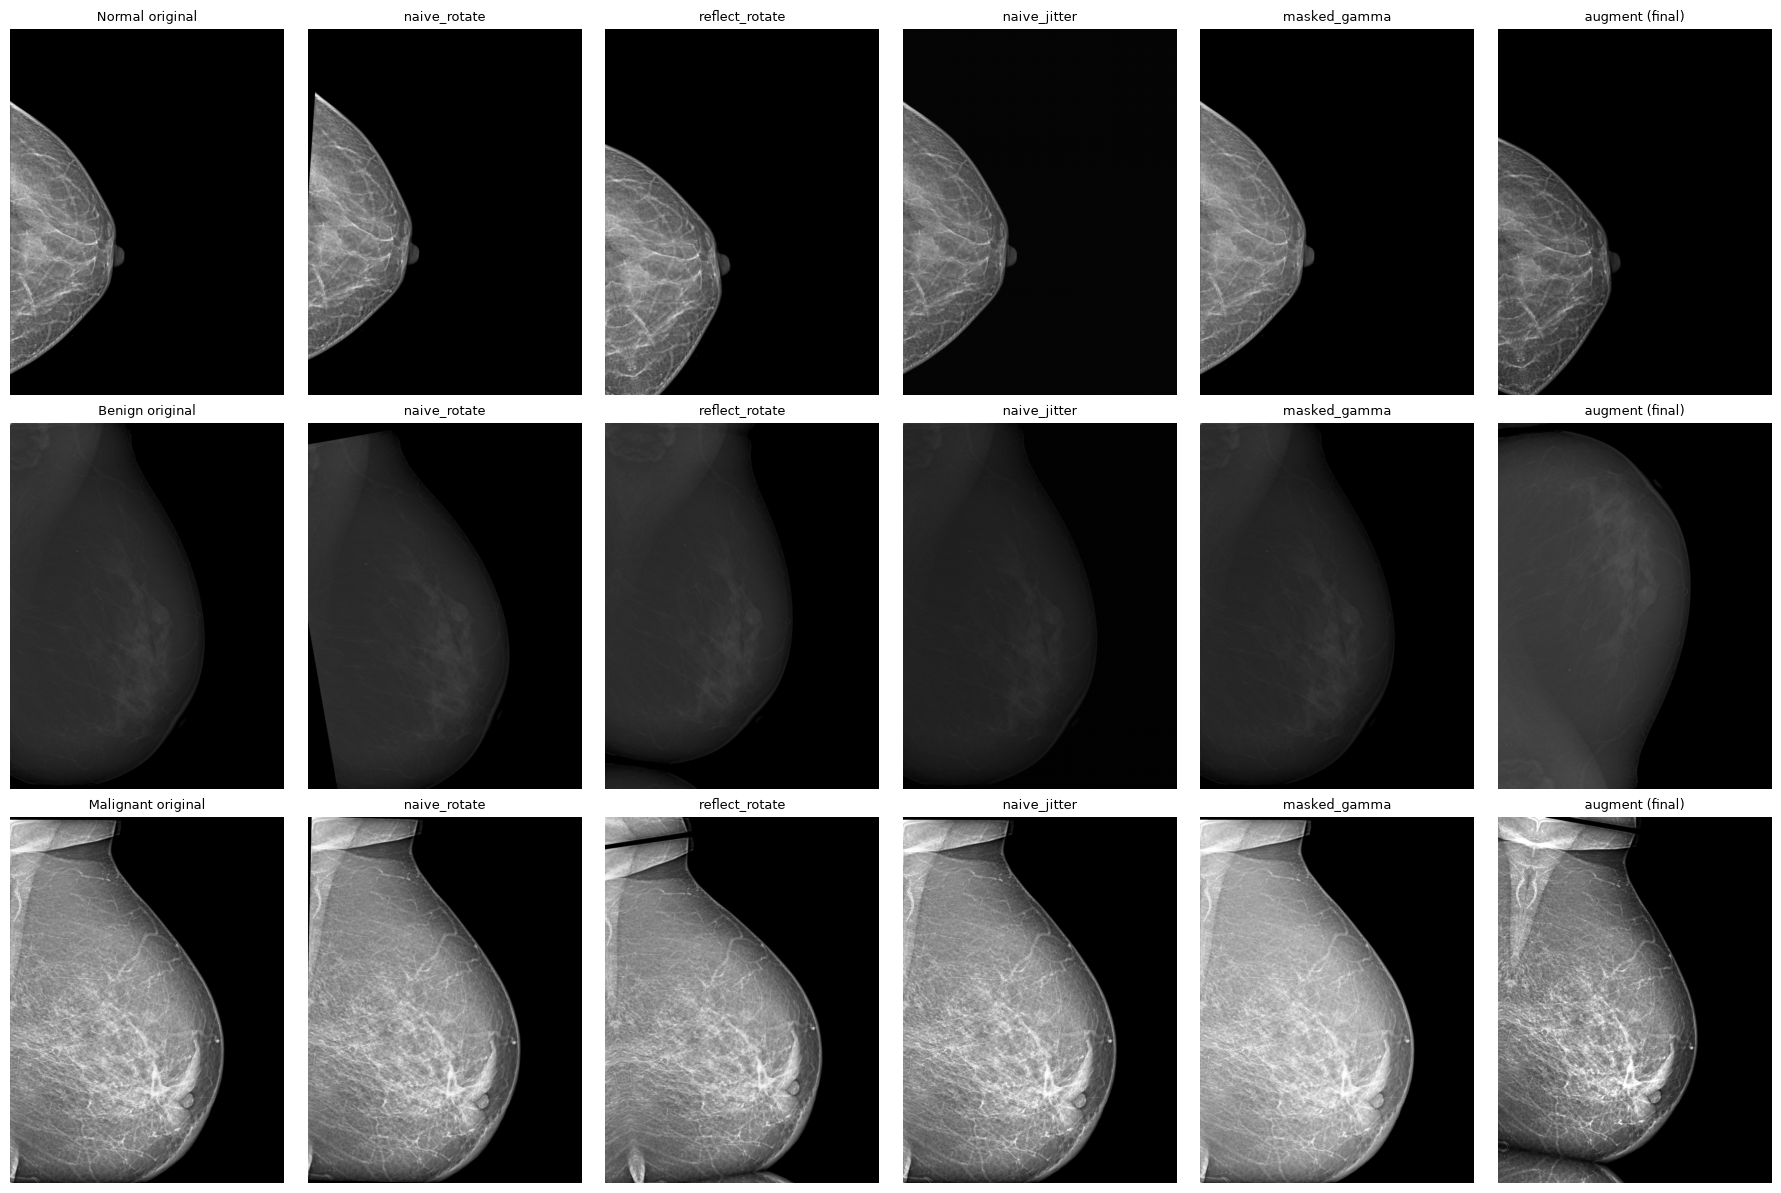

In [19]:
np.random.seed(CFG.SEED)
pk = [df[df.label == l].sample(1, random_state=3).index[0] for l in CFG.CLASSES]
fig, ax = plt.subplots(3, 1 + len(AUGS), figsize=(3 * (1 + len(AUGS)), 12))
for r, k in enumerate(pk):
    x = small(IMAGES[k])
    ax[r, 0].imshow(x, cmap='gray', vmin=0, vmax=1)
    ax[r, 0].set_title(f'{df.label[k]} original', fontsize=9)
    for c, (name, fn) in enumerate(AUGS.items(), 1):
        ax[r, c].imshow(fn(x), cmap='gray', vmin=0, vmax=1)
        ax[r, c].set_title(name, fontsize=9)
for a in ax.flat:
    a.axis('off')
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / 'augmentations.png', dpi=60)
plt.show()

#### Insights

> Rotasi biasa sebesar 15 derajat meninggalkan irisan hitam di dinding dada pada sekitar 44% tepi kiri. Pola ini tidak pernah ada di data uji, sehingga model bisa belajar bahwa irisan berarti data latih. Memindahkan titik putar ke dinding dada tidak membantu (wedge tetap sekitar 0.4), sedangkan border reflect menurunkannya ke sekitar 0.02. Rotasi 45 derajat ala paper ETECADx bahkan memotong hingga 26% jaringan, sehingga sudutnya dibatasi 15 derajat.

> ColorJitter mengangkat background hitam menjadi abu-abu karena kontras dicampur dengan rata-rata citra, dan pada citra yang sudah gelap ia juga meruntuhkan kontras jaringan. `masked_gamma` menjaga background tetap nol (bg_lift 0) sambil tetap memvariasikan windowing.

---

# Training <a name="8"></a>

---

EfficientNet-B3 pretrained dilatih dengan input satu channel (timm menjumlahkan bobot stem RGB) pada resolusi 1024x768. Training memakai 5 fold StratifiedGroupKFold berbasis grup pasien dan mixed precision bf16 pada satu RTX 5090. Karena rentang eksponen bf16 sama dengan fp32, gradient scaling tidak diperlukan. Model yang disimpan adalah model dari epoch terakhir, karena memilih epoch terbaik pada fold validasi sekecil ini akan membuat skor OOF bias ke atas.

## Dataset dan Model

Dataset membaca kanvas dari cache di memori, mengecilkannya ke resolusi training, lalu menerapkan augmentasi hanya pada data latih. Setiap worker DataLoader diberi seed NumPy sendiri agar augmentasi antar worker tidak identik.

In [20]:
if 'emb_net' in globals():
    del emb_net
    torch.cuda.empty_cache()

class MammoDataset(Dataset):
    def __init__(self, images, labels, train):
        self.images, self.labels, self.train = images, labels, train

    def __len__(self):
        return len(self.images)

    def __getitem__(self, i):
        a = small(self.images[i])
        if self.train:
            a = augment(a)
        x = (torch.from_numpy(a)[None] - CFG.PIX_MEAN) / CFG.PIX_STD
        return x, int(self.labels[i])

def worker_init(worker_id):
    np.random.seed((torch.initial_seed() + worker_id) % 2**32)

def build_model(pretrained=True):
    m = timm.create_model(CFG.ARCH, pretrained=pretrained, num_classes=len(CFG.CLASSES), in_chans=1, drop_rate=CFG.DROP)
    return m.to(CFG.DEVICE, memory_format=torch.channels_last)

def autocast():
    return torch.autocast('cuda', dtype=CFG.AMP_DTYPE, enabled=CFG.DEVICE == 'cuda')

@torch.no_grad()
def predict(model, images):
    model.eval()
    dl = DataLoader(MammoDataset(images, np.zeros(len(images)), False), batch_size=CFG.BATCH * 2,
                    shuffle=False, num_workers=CFG.NUM_WORKERS)
    out = []
    for x, _ in dl:
        x = x.to(CFG.DEVICE, memory_format=torch.channels_last)
        with autocast():
            # TTA: identitas + vertical flip (dim 2 = tinggi)
            p = model(x).float().softmax(1) + model(x.flip(2)).float().softmax(1)
        out.append((p / 2).cpu().numpy())
    return np.concatenate(out)

## Training Loop

Setiap fold memakai AdamW dengan OneCycle (warmup 10%), cross entropy berbobot kelas (kebalikan frekuensi) dengan label smoothing 0.1, dan autocast bf16. Macro F1 validasi dicatat per epoch hanya untuk memantau kurva, bukan untuk memilih model. Puncak memori GPU dicetak di akhir setiap fold sebagai acuan jika `BATCH` atau resolusi ingin dinaikkan.

In [21]:
X_tr, y_tr, g_tr = IMAGES[is_train], y_all[is_train], df.group.values[is_train]

def train_fold(fold, tr_idx, va_idx):
    seed_everything(CFG.SEED + fold)
    model = build_model()
    dl = DataLoader(MammoDataset(X_tr[tr_idx], y_tr[tr_idx], True), batch_size=CFG.BATCH, shuffle=True,
                    drop_last=True, num_workers=CFG.NUM_WORKERS, worker_init_fn=worker_init, pin_memory=True)
    opt = torch.optim.AdamW(model.parameters(), lr=CFG.LR, weight_decay=CFG.WD)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=CFG.LR, total_steps=CFG.EPOCHS * len(dl), pct_start=CFG.WARMUP)
    # bobot kelas = N / (K * n_c)
    w = len(tr_idx) / (len(CFG.CLASSES) * np.bincount(y_tr[tr_idx], minlength=len(CFG.CLASSES)))
    crit = nn.CrossEntropyLoss(weight=torch.tensor(w, dtype=torch.float32, device=CFG.DEVICE), label_smoothing=CFG.SMOOTHING)
    if CFG.DEVICE == 'cuda':
        torch.cuda.reset_peak_memory_stats()
    history = []
    for ep in range(CFG.EPOCHS):
        model.train()
        t0, total = time.time(), 0.0
        for x, yb in dl:
            x = x.to(CFG.DEVICE, non_blocking=True, memory_format=torch.channels_last)
            yb = yb.to(CFG.DEVICE)
            with autocast():
                loss = crit(model(x).float(), yb)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            sched.step()
            total += loss.item()
        p = predict(model, X_tr[va_idx])
        f1 = f1_score(y_tr[va_idx], p.argmax(1), average='macro')
        history.append(dict(fold=fold, epoch=ep, loss=total / len(dl), val_f1=f1))
        print(f'fold {fold} ep {ep:02d}  loss {total / len(dl):.4f}  val macroF1 {f1:.3f}  {time.time() - t0:.0f}s')
    if CFG.DEVICE == 'cuda':
        print(f'fold {fold} peak GPU memory {torch.cuda.max_memory_allocated() / 1e9:.1f} GB')
    torch.save(model.state_dict(), CFG.WEIGHTS_DIR / f'fold{fold}.pt')
    return p, history

folds = list(StratifiedGroupKFold(CFG.N_FOLDS, shuffle=True, random_state=CFG.SEED).split(X_tr, y_tr, g_tr))
for a, b in folds:
    assert not set(g_tr[a]) & set(g_tr[b])
print('fold sizes:', [len(b) for _, b in folds])

if CFG.RUN_NAME == 'TRAIN':
    OOF, HISTORY = np.zeros((len(y_tr), len(CFG.CLASSES))), []
    for f, (a, b) in enumerate(folds):
        OOF[b], h = train_fold(f, a, b)
        HISTORY += h
    np.save(CFG.WEIGHTS_DIR / 'oof.npy', OOF)
    pd.DataFrame(HISTORY).to_csv(CFG.WEIGHTS_DIR / 'history.csv', index=False)
else:
    OOF = np.load(CFG.WEIGHTS_DIR / 'oof.npy')
    HISTORY = pd.read_csv(CFG.WEIGHTS_DIR / 'history.csv').to_dict('records')

fold sizes: [43, 42, 42, 43, 42]


model.safetensors: reconstructing file:   0%|          |  0.00B / 49.3MB            

model.safetensors: downloading bytes:           |  0.00B            

fold 0 ep 00  loss 1.7675  val macroF1 0.291  66s
fold 0 ep 01  loss 1.7801  val macroF1 0.276  3s
fold 0 ep 02  loss 1.3911  val macroF1 0.329  3s
fold 0 ep 03  loss 1.1873  val macroF1 0.464  3s
fold 0 ep 04  loss 1.2538  val macroF1 0.458  3s
fold 0 ep 05  loss 1.1365  val macroF1 0.440  3s
fold 0 ep 06  loss 0.8895  val macroF1 0.506  3s
fold 0 ep 07  loss 0.7657  val macroF1 0.535  3s
fold 0 ep 08  loss 0.7572  val macroF1 0.539  3s
fold 0 ep 09  loss 0.7973  val macroF1 0.537  3s
fold 0 ep 10  loss 0.5888  val macroF1 0.503  3s
fold 0 ep 11  loss 0.5470  val macroF1 0.547  3s
fold 0 ep 12  loss 0.5891  val macroF1 0.602  3s
fold 0 ep 13  loss 0.4891  val macroF1 0.641  3s
fold 0 ep 14  loss 0.5412  val macroF1 0.563  3s
fold 0 ep 15  loss 0.4869  val macroF1 0.616  3s
fold 0 ep 16  loss 0.5005  val macroF1 0.614  3s
fold 0 ep 17  loss 0.4617  val macroF1 0.643  3s
fold 0 ep 18  loss 0.4926  val macroF1 0.588  3s
fold 0 ep 19  loss 0.4694  val macroF1 0.617  3s
fold 0 peak GPU mem

fold 1 ep 00  loss 1.8539  val macroF1 0.314  17s
fold 1 ep 01  loss 1.7705  val macroF1 0.435  3s
fold 1 ep 02  loss 1.6798  val macroF1 0.396  3s
fold 1 ep 03  loss 1.4334  val macroF1 0.312  3s
fold 1 ep 04  loss 1.0626  val macroF1 0.347  3s
fold 1 ep 05  loss 0.8891  val macroF1 0.520  3s
fold 1 ep 06  loss 0.8961  val macroF1 0.505  3s
fold 1 ep 07  loss 0.8433  val macroF1 0.435  3s
fold 1 ep 08  loss 0.7695  val macroF1 0.397  3s
fold 1 ep 09  loss 0.6661  val macroF1 0.490  3s
fold 1 ep 10  loss 0.5755  val macroF1 0.655  3s
fold 1 ep 11  loss 0.6308  val macroF1 0.602  3s
fold 1 ep 12  loss 0.5106  val macroF1 0.626  3s
fold 1 ep 13  loss 0.5026  val macroF1 0.542  3s
fold 1 ep 14  loss 0.5360  val macroF1 0.612  3s
fold 1 ep 15  loss 0.4991  val macroF1 0.570  3s
fold 1 ep 16  loss 0.5401  val macroF1 0.534  3s
fold 1 ep 17  loss 0.4952  val macroF1 0.557  3s
fold 1 ep 18  loss 0.5012  val macroF1 0.575  3s
fold 1 ep 19  loss 0.4352  val macroF1 0.596  3s
fold 1 peak GPU mem

## Evaluasi Out-of-Fold

Prediksi out-of-fold dari kelima fold digabung untuk menghitung macro F1, F1 per kelas, dan confusion matrix. Kurva macro F1 validasi per epoch dipakai untuk menilai apakah jumlah epoch sudah tepat.

OOF macro F1: 0.6410
F1 per kelas: {'Normal': np.float64(0.722), 'Benign': np.float64(0.509), 'Malignant': np.float64(0.692)}


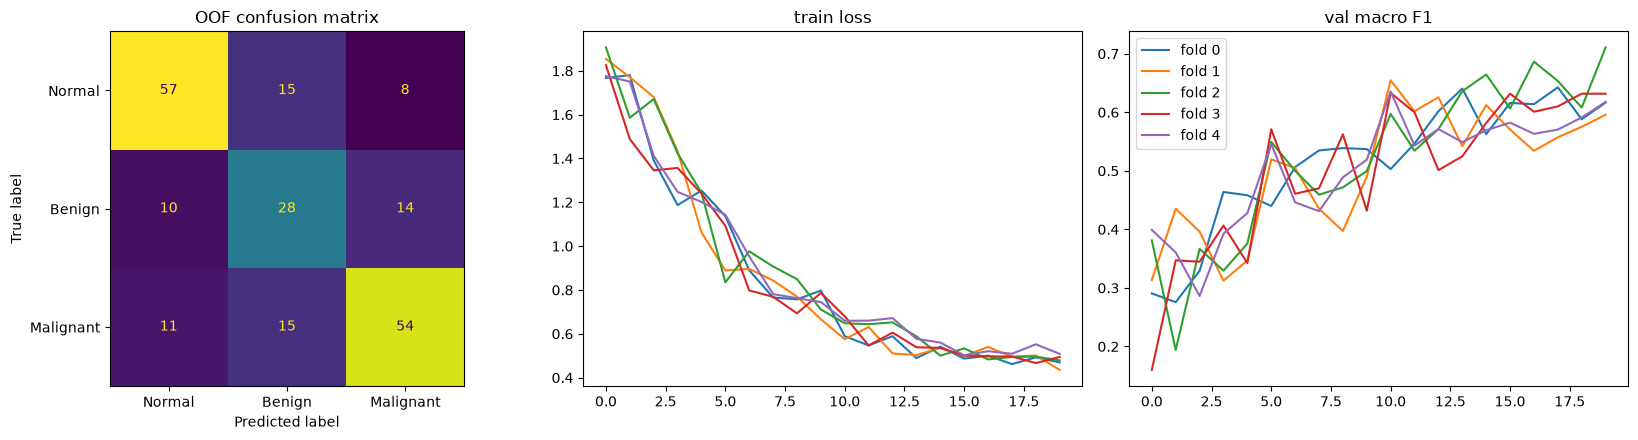

In [22]:
oof_pred = OOF.argmax(1)
print(f'OOF macro F1: {f1_score(y_tr, oof_pred, average="macro"):.4f}')
print('F1 per kelas:', dict(zip(CFG.CLASSES, f1_score(y_tr, oof_pred, average=None).round(3))))

hist = pd.DataFrame(HISTORY)
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_tr, oof_pred), display_labels=CFG.CLASSES).plot(ax=ax[0], colorbar=False)
ax[0].set_title('OOF confusion matrix')
for f, g in hist.groupby('fold'):
    ax[1].plot(g.epoch, g.loss, label=f'fold {f}')
    ax[2].plot(g.epoch, g.val_f1, label=f'fold {f}')
ax[1].set_title('train loss')
ax[2].set_title('val macro F1')
ax[2].legend()
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / 'oof_eval.png', dpi=90)
plt.show()

#### Insights

> Berdasarkan EDA, sebagian besar kesalahan diperkirakan terjadi antara Benign dan Malignant. Label keduanya berasal dari kategori BI-RADS (2-3 vs 4-5) yang merupakan kesan radiolog, bukan hasil biopsi, sehingga batasnya memang kabur. Normal vs Abnormal biasanya lebih mudah dipisahkan.

> Jika kurva val macro F1 masih naik di epoch terakhir, `EPOCHS` bisa dinaikkan. Jika kurva turun sementara loss train terus turun, model mulai overfit dan `EPOCHS` perlu dikurangi. Dengan sekitar 42 citra per fold, fluktuasi antar fold sebesar 0.05-0.1 masih wajar.

## Kalibrasi Bobot Kelas

Macro F1 sensitif terhadap threshold kelas minoritas. Pengali probabilitas untuk Benign dan Malignant dicari dengan grid kasar (0.6 sampai 1.6) pada OOF. Grid sengaja dibuat kasar dan hasilnya hanya dipakai bila kenaikannya cukup besar, karena 212 sampel mudah membuat threshold overfit.

In [23]:
def tune_scale(P, y, min_gain=0.01):
    base = f1_score(y, P.argmax(1), average='macro')
    best_s, best_w = base, np.ones(len(CFG.CLASSES))
    grid = np.round(np.arange(0.6, 1.61, 0.1), 2)
    for wb in grid:
        for wm in grid:
            w = np.array([1.0, wb, wm])
            s = f1_score(y, (P * w).argmax(1), average='macro')
            if s > best_s + 1e-9:
                best_s, best_w = s, w
    if best_s - base < min_gain:
        best_s, best_w = base, np.ones(len(CFG.CLASSES))
    return base, best_s, best_w

base_f1, tuned_f1, CLASS_W = tune_scale(OOF, y_tr)
print(f'OOF macro F1 argmax={base_f1:.4f}  dengan bobot={tuned_f1:.4f}  bobot={CLASS_W.tolist()}')
json.dump({'class_w': CLASS_W.tolist(), 'oof_f1': tuned_f1}, open(CFG.OUTPUT_DIR / 'class_w.json', 'w'))

OOF macro F1 argmax=0.6410  dengan bobot=0.6410  bobot=[1.0, 1.0, 1.0]


---

# Inference dan Submission <a name="9"></a>

---

Citra uji melewati preprocessing yang identik dengan data latih, karena cache dibangun sekaligus untuk 266 citra. Probabilitas dari lima model fold dirata-rata dengan TTA vertical flip, lalu dikalikan bobot kelas dari OOF. Submission divalidasi terhadap format `sample_submission.csv` sebelum disimpan.

## Prediksi Ensemble

Bobot kelima fold dimuat dari `WEIGHTS_DIR`, baik hasil training barusan maupun bobot yang diunggah untuk mode INFERENCE.

In [24]:
X_te = IMAGES[~is_train]
P_te = np.zeros((len(X_te), len(CFG.CLASSES)))
for f in range(CFG.N_FOLDS):
    model = build_model(pretrained=False)
    model.load_state_dict(torch.load(CFG.WEIGHTS_DIR / f'fold{f}.pt', map_location=CFG.DEVICE))
    P_te += predict(model, X_te) / CFG.N_FOLDS
    del model
    torch.cuda.empty_cache()
np.save(CFG.OUTPUT_DIR / 'test_probs.npy', P_te)

pred = (P_te * CLASS_W).argmax(1)
print('distribusi prediksi test:', pd.Series([CFG.CLASSES[k] for k in pred]).value_counts().to_dict())
print('distribusi OOF train    :', pd.Series([CFG.CLASSES[k] for k in (OOF * CLASS_W).argmax(1)]).value_counts().to_dict())

distribusi prediksi test: {'Normal': 24, 'Malignant': 18, 'Benign': 12}
distribusi OOF train    : {'Normal': 78, 'Malignant': 76, 'Benign': 58}


## Simpan Submission

Urutan baris mengikuti `sample_submission.csv`. Setiap `image_id` harus muncul tepat sekali dengan label yang valid.

In [25]:
sample = pd.read_csv(CFG.DATA_DIR / 'sample_submission.csv')
sub = pd.DataFrame({'image_id': df.image_id[~is_train].values, 'label': [CFG.CLASSES[k] for k in pred]})
sub = sample[['image_id']].merge(sub, on='image_id', how='left')

assert len(sub) == len(sample) and sub.image_id.is_unique
assert sub.label.notna().all() and set(sub.label) <= set(CFG.CLASSES)
sub.to_csv(CFG.OUTPUT_DIR / 'submission.csv', index=False)
print(sub.head())
print(f'saved {CFG.OUTPUT_DIR / "submission.csv"}  rows={len(sub)}')

         image_id      label
0  image_0002.jpg     Normal
1  image_0014.jpg  Malignant
2  image_0016.jpg     Normal
3  image_0021.jpg     Normal
4  image_0023.jpg     Normal
saved output/submission.csv  rows=54


## Sampel Prediksi

Beberapa citra uji ditampilkan dengan label prediksi dan probabilitasnya sebagai sanity check visual terakhir.

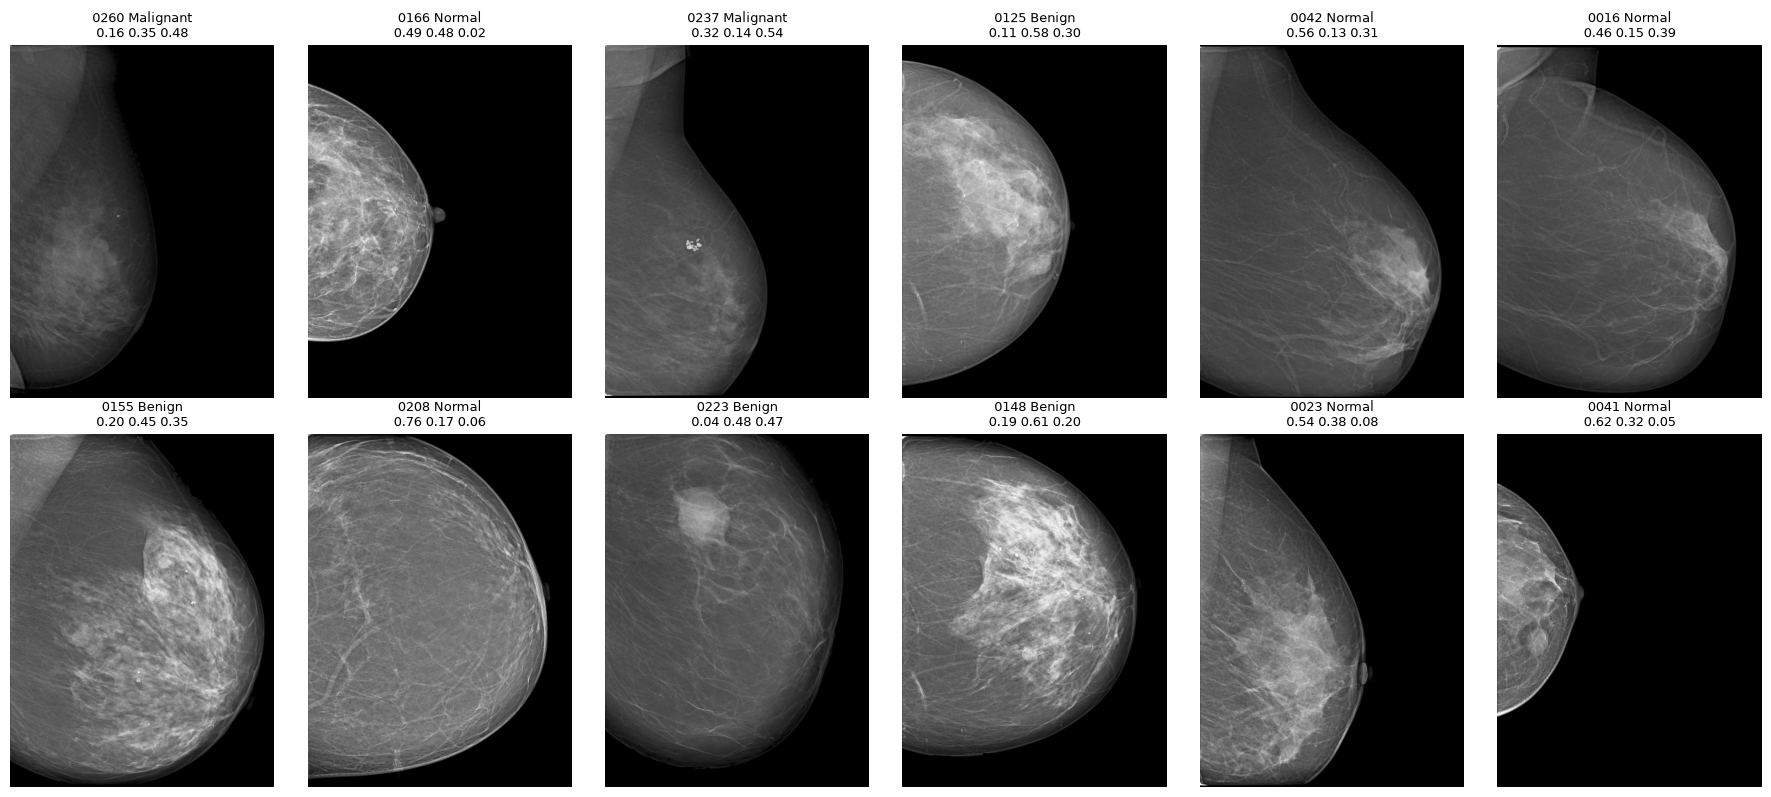

In [26]:
te_ids = df.image_id[~is_train].values
fig, ax = plt.subplots(2, 6, figsize=(18, 8))
for a, k in zip(ax.flat, np.random.RandomState(0).choice(len(X_te), 12, replace=False)):
    a.imshow(X_te[k], cmap='gray')
    a.set_title(f'{te_ids[k][6:10]} {CFG.CLASSES[pred[k]]}\n' + ' '.join(f'{p:.2f}' for p in P_te[k]), fontsize=9)
    a.axis('off')
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / 'test_predictions.png', dpi=70)
plt.show()

#### Insights

> Distribusi prediksi test sebaiknya berada di kisaran proporsi train (sekitar 38% Normal, 25% Benign, 38% Malignant). Jika satu kelas mendominasi, bobot kelas atau jumlah epoch perlu diperiksa ulang.

> Langkah pengembangan berikutnya yang paling menjanjikan menurut literatur adalah fusi dua view (CC dan MLO) per pasien serta resolusi input yang lebih tinggi untuk mikrokalsifikasi. Keduanya perlu divalidasi dengan grouped CV yang sama.